# Original Nutrition Dataset — Exploratory Data Analysis (EDA)

**Project phase:** Original dataset analysis (before API collection and data fusion)  
**Dataset:** `Original_nutrition_base.csv`

This notebook performs a complete initial EDA: loading and inspecting the dataset, checking data quality, cleaning numeric fields, summarizing nutritional attributes, identifying distributions and outliers, and exploring relationships between nutrients.

> Run the cells in order. The notebook uses the Google Drive path supplied for this project.


## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 110

## 2. Load the original dataset

In [2]:
from google.colab import drive
drive.mount('/content/drive')

file_path = "/content/drive/MyDrive/phase1/Original_nutrition_base.csv"

df = pd.read_csv(file_path)

# Preserve an unchanged copy for comparison during cleaning
df_original = df.copy(deep=True)

print("Dataset loaded successfully!")
print("Dataset name: Original_nutrition_base.csv")
print("Shape:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())

print("\\nFirst five records:")
display(df.head())

Mounted at /content/drive
Dataset loaded successfully!
Dataset name: Original_nutrition_base.csv
Shape: (8789, 15)
\nColumn names:
['Food Name', 'serving_size', 'calories', 'total_fat', 'saturated_fat', 'carbohydrate', 'fiber', 'sugars', 'sodium', 'calcium', 'iron', 'potassium', 'vitamin_c', 'folate', 'protein']
\nFirst five records:


,Food Name,serving_size,calories,total_fat,saturated_fat,carbohydrate,fiber,sugars,sodium,calcium,iron,potassium,vitamin_c,folate,protein
0,Cornstarch,100 g,381,0.1g,NaN,91.27 g,0.9 g,0.00 g,9.00 mg,2.00 mg,0.47 mg,3.00 mg,0.0 mg,0.00 mcg,0.26 g
1,"Nuts, pecans",100 g,691,72g,6.2g,13.86 g,9.6 g,3.97 g,0.00 mg,70.00 mg,2.53 mg,410.00 mg,1.1 mg,22.00 mcg,9.17 g
2,"Eggplant, raw",100 g,25,0.2g,NaN,5.88 g,3.0 g,3.53 g,2.00 mg,9.00 mg,0.23 mg,229.00 mg,2.2 mg,22.00 mcg,0.98 g
3,"Teff, uncooked",100 g,367,2.4g,0.4g,73.13 g,8.0 g,1.84 g,12.00 mg,180.00 mg,7.63 mg,427.00 mg,0,0,13.30 g
4,"Sherbet, orange",100 g,144,2g,1.2g,30.40 g,1.3 g,24.32 g,46.00 mg,54.00 mg,0.14 mg,96.00 mg,2.3 mg,4.00 mcg,1.10 g


## 3. Dataset overview and structure

In [3]:
print("Number of records:", df.shape[0])
print("Number of attributes:", df.shape[1])
print("\\nDataset information:")
df.info()

print("\\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\\nRandom sample of records:")
display(df.sample(min(5, len(df)), random_state=42))

Number of records: 8789
Number of attributes: 15
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8789 entries, 0 to 8788
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Food Name      8789 non-null   object
 1   serving_size   8789 non-null   object
 2   calories       8789 non-null   int64 
 3   total_fat      8789 non-null   object
 4   saturated_fat  7199 non-null   object
 5   carbohydrate   8789 non-null   object
 6   fiber          8789 non-null   object
 7   sugars         8789 non-null   object
 8   sodium         8789 non-null   object
 9   calcium        8789 non-null   object
 10  iron           8789 non-null   object
 11  potassium      8789 non-null   object
 12  vitamin_c      8789 non-null   object
 13  folate         8789 non-null   object
 14  protein        8789 non-null   object
dtypes: int64(1), object(14)
memory usage: 1.0+ MB
\nData types:


,Data Type
Food Name,object
serving_size,object
calories,int64
total_fat,object
saturated_fat,object
carbohydrate,object
fiber,object
sugars,object
sodium,object
calcium,object


\nRandom sample of records:


,Food Name,serving_size,calories,total_fat,saturated_fat,carbohydrate,fiber,sugars,sodium,calcium,iron,potassium,vitamin_c,folate,protein
1839,"Game meat, roasted, cooked, elk",100 g,146,1.9g,0.7g,0.00 g,0.0 g,0,61.00 mg,5.00 mg,3.63 mg,328.00 mg,0.0 mg,9.00 mcg,30.19 g
3362,"KASHI, Original, H2H Woven Wheat Cracker",100 g,396,12g,1.1g,73.40 g,12.2 g,0.40 g,283.00 mg,40.00 mg,6.00 mg,418.00 mg,20.0 mg,333.00 mcg,10.60 g
2373,"Beverages, Cran Lemonade, OCEAN SPRAY",100 g,45,0g,NaN,11.12 g,0.6 g,10.40 g,52.00 mg,2.00 mg,0.03 mg,10.00 mg,32.6 mg,0,0.07 g
7250,"Beans, without salt, drained, boiled, cooked, ...",100 g,162,0.5g,0.1g,30.87 g,5.4 g,0,83.00 mg,52.00 mg,2.71 mg,646.00 mg,0.7 mg,34.00 mcg,9.31 g
8139,"Pork, broiled, cooked, separable lean only, bo...",100 g,186,8.4g,2.8g,0.00 g,0.0 g,0.00 g,57.00 mg,26.00 mg,0.68 mg,343.00 mg,0.0 mg,0.00 mcg,25.79 g


## 4. Identify important attributes

In [4]:
print("Attributes in the dataset:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

Attributes in the dataset:
1. Food Name
2. serving_size
3. calories
4. total_fat
5. saturated_fat
6. carbohydrate
7. fiber
8. sugars
9. sodium
10. calcium
11. iron
12. potassium
13. vitamin_c
14. folate
15. protein


### Attribute descriptions

- **Food Name:** Name/description of the food item.
- **serving_size:** Reference quantity used for the nutritional values.
- **calories:** Energy provided by the food.
- **total_fat, saturated_fat:** Total and saturated fat content.
- **carbohydrate:** Carbohydrate content.
- **fiber, sugars:** Dietary fiber and sugar content.
- **sodium:** Sodium content.
- **calcium, iron, potassium:** Mineral content.
- **vitamin_c, folate:** Vitamin content.
- **protein:** Protein content.

Check the source documentation before treating units as identical across every field. This dataset appears to use a mixture of units (for example, grams, milligrams and micrograms).


## 5. Data quality — missing values

,Missing Values,Missing Percentage (%)
saturated_fat,1590,18.09
serving_size,0,0.00
Food Name,0,0.00
calories,0,0.00
total_fat,0,0.00
carbohydrate,0,0.00
fiber,0,0.00
sugars,0,0.00
sodium,0,0.00
calcium,0,0.00


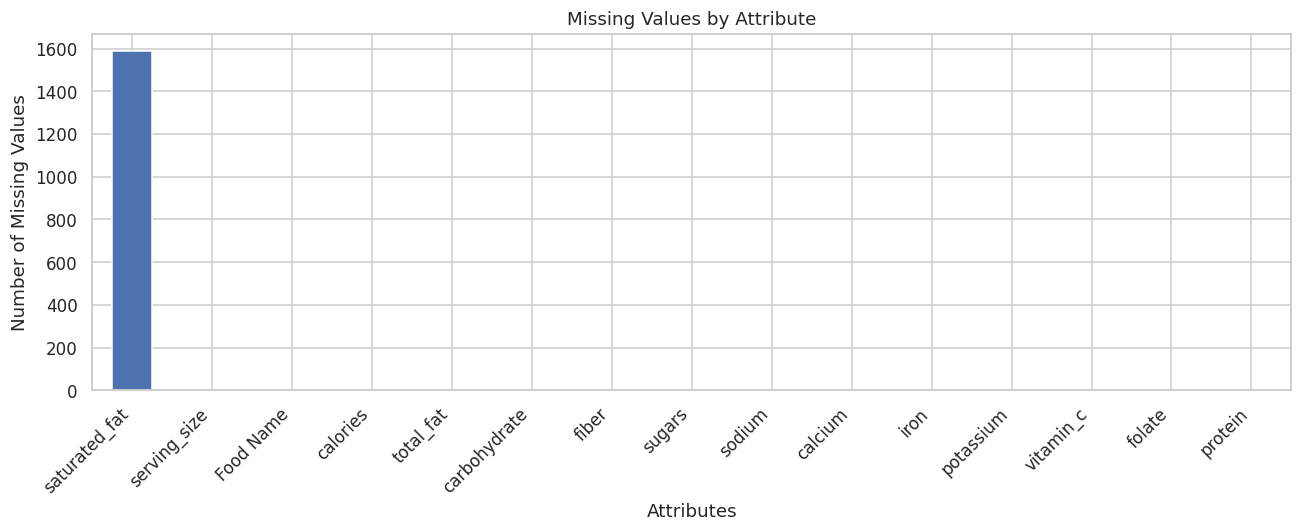

In [5]:
missing_count = df.isna().sum()
missing_percent = (df.isna().mean() * 100).round(2)

missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage (%)": missing_percent
}).sort_values("Missing Percentage (%)", ascending=False)

display(missing_summary)

plt.figure(figsize=(12, 5))
missing_summary["Missing Values"].plot(kind="bar")
plt.title("Missing Values by Attribute")
plt.xlabel("Attributes")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 6. Duplicate records and duplicate food names

In [6]:
duplicate_rows = df.duplicated().sum()
duplicate_food_names = df["Food Name"].duplicated().sum() if "Food Name" in df.columns else None

print("Exact duplicate rows:", duplicate_rows)
if duplicate_food_names is not None:
    print("Repeated food names:", duplicate_food_names)

if duplicate_rows > 0:
    display(df[df.duplicated(keep=False)].head(10))

if "Food Name" in df.columns:
    repeated_names = df[df["Food Name"].duplicated(keep=False)].sort_values("Food Name")
    print("\\nRepeated food names (if any):")
    display(repeated_names.head(20))

Exact duplicate rows: 0
Repeated food names: 0
\nRepeated food names (if any):


,Food Name,serving_size,calories,total_fat,saturated_fat,carbohydrate,fiber,sugars,sodium,calcium,iron,potassium,vitamin_c,folate,protein


## 7. Prepare numerical attributes for analysis

In [7]:
# Convert nutrient columns to numeric values.
# This removes common unit strings (g, mg, mcg, kcal) and commas.
numeric_candidates = [col for col in df.columns if col not in ["Food Name", "serving_size"]]

df_eda = df.copy()

for col in numeric_candidates:
    cleaned = (
        df_eda[col].astype(str)
        .str.replace(",", "", regex=False)
        .str.replace(r"[^0-9.\\-]", "", regex=True)
        .replace("", np.nan)
    )
    df_eda[col] = pd.to_numeric(cleaned, errors="coerce")

print("Numeric conversion completed.")
print("Numeric columns:")
print(df_eda.select_dtypes(include=np.number).columns.tolist())

display(df_eda.head())

Numeric conversion completed.
Numeric columns:
['calories', 'total_fat', 'saturated_fat', 'carbohydrate', 'fiber', 'sugars', 'sodium', 'calcium', 'iron', 'potassium', 'vitamin_c', 'folate', 'protein']


,Food Name,serving_size,calories,total_fat,saturated_fat,carbohydrate,fiber,sugars,sodium,calcium,iron,potassium,vitamin_c,folate,protein
0,Cornstarch,100 g,381,0.1,NaN,91.27,0.9,0.00,9.0,2.0,0.47,3.0,0.0,0.0,0.26
1,"Nuts, pecans",100 g,691,72.0,6.2,13.86,9.6,3.97,0.0,70.0,2.53,410.0,1.1,22.0,9.17
2,"Eggplant, raw",100 g,25,0.2,NaN,5.88,3.0,3.53,2.0,9.0,0.23,229.0,2.2,22.0,0.98
3,"Teff, uncooked",100 g,367,2.4,0.4,73.13,8.0,1.84,12.0,180.0,7.63,427.0,0.0,0.0,13.30
4,"Sherbet, orange",100 g,144,2.0,1.2,30.40,1.3,24.32,46.0,54.0,0.14,96.0,2.3,4.0,1.10


## 8. Descriptive statistics

In [8]:
numeric_df = df_eda.select_dtypes(include=np.number)

descriptive_stats = numeric_df.describe().T
descriptive_stats["missing"] = numeric_df.isna().sum()
descriptive_stats["missing_percent"] = (numeric_df.isna().mean() * 100).round(2)

display(descriptive_stats.round(3))

,count,mean,std,min,25%,50%,75%,max,missing,missing_percent
calories,8789.0,226.284,169.862,0.0,91.00,191.00,337.00,902.00,0,0.00
total_fat,8789.0,10.557,15.818,0.0,1.00,5.10,14.00,100.00,0,0.00
saturated_fat,7199.0,4.193,6.877,0.1,0.70,2.20,5.00,96.00,1590,18.09
carbohydrate,8789.0,22.122,27.266,0.0,0.05,9.34,34.91,100.00,0,0.00
fiber,8789.0,2.040,4.269,0.0,0.00,0.40,2.40,79.00,0,0.00
sugars,8789.0,6.756,13.719,0.0,0.00,0.49,6.05,99.80,0,0.00
sodium,8789.0,306.354,939.220,0.0,36.00,84.00,396.00,38758.00,0,0.00
calcium,8789.0,73.317,199.850,0.0,8.00,19.00,63.00,7364.00,0,0.00
iron,8789.0,2.646,5.661,0.0,0.49,1.31,2.57,123.60,0,0.00
potassium,8789.0,265.251,371.444,0.0,111.00,219.00,329.00,16500.00,0,0.00


## 9. Distribution analysis — histograms

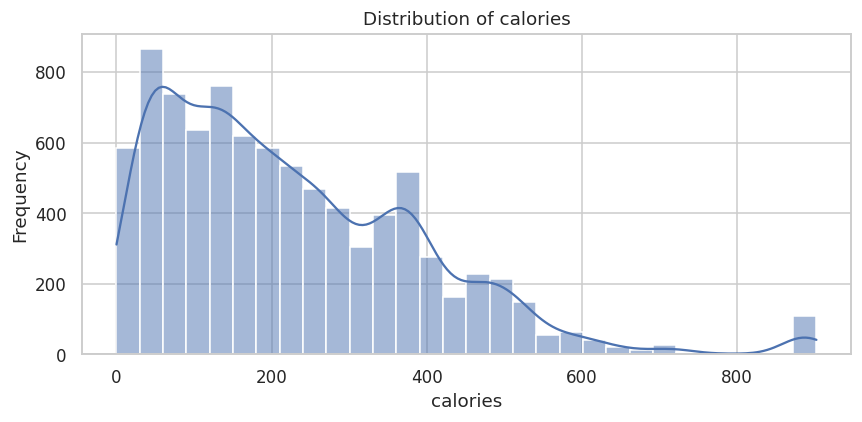

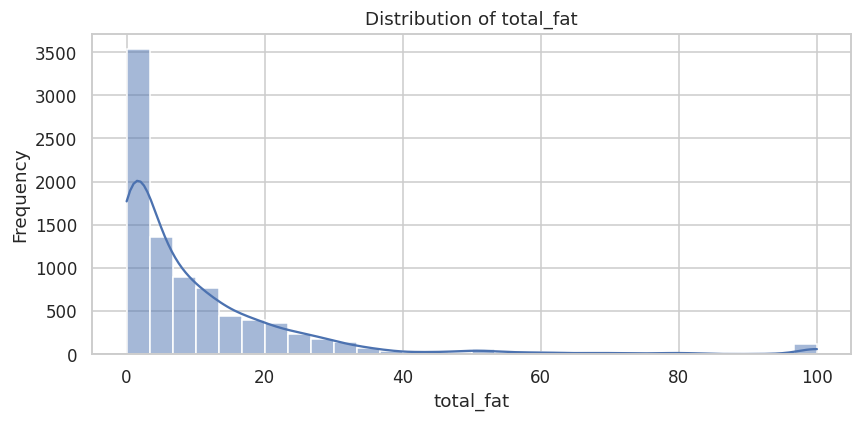

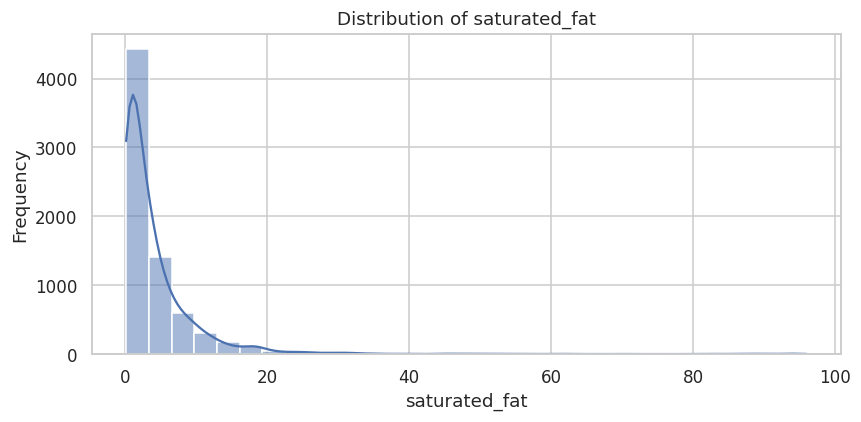

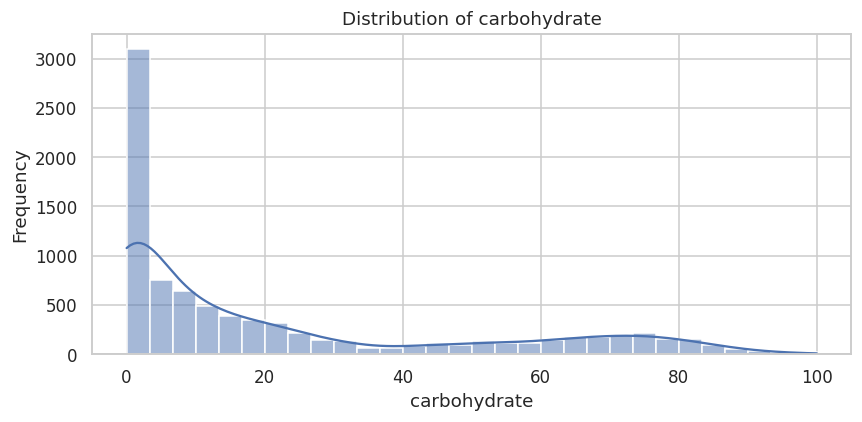

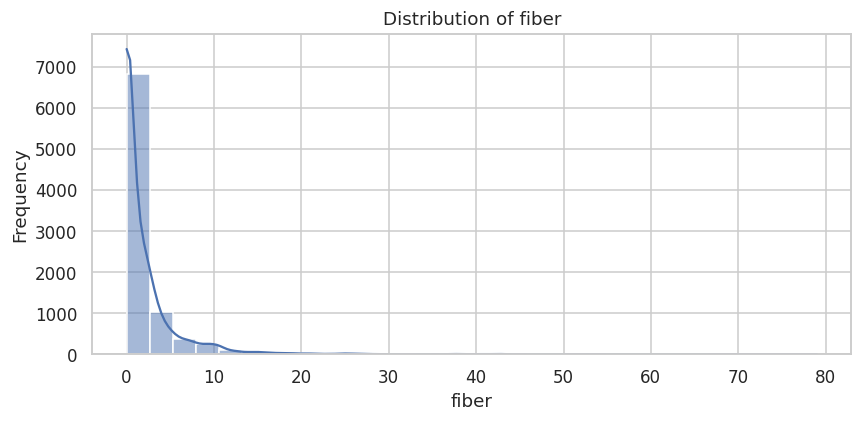

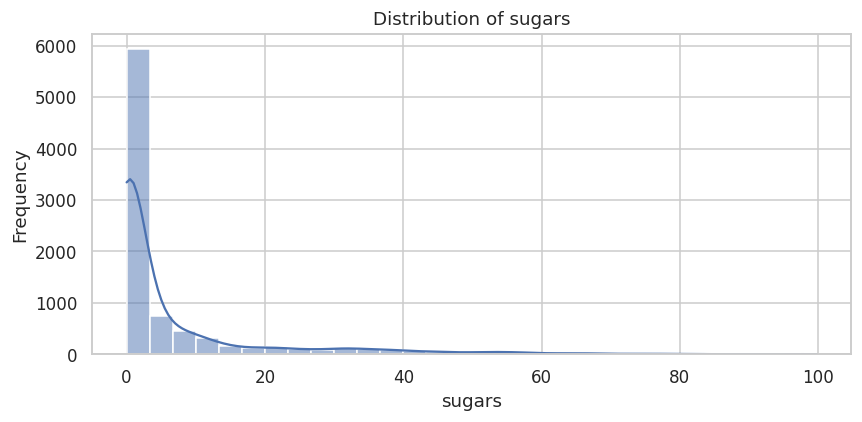

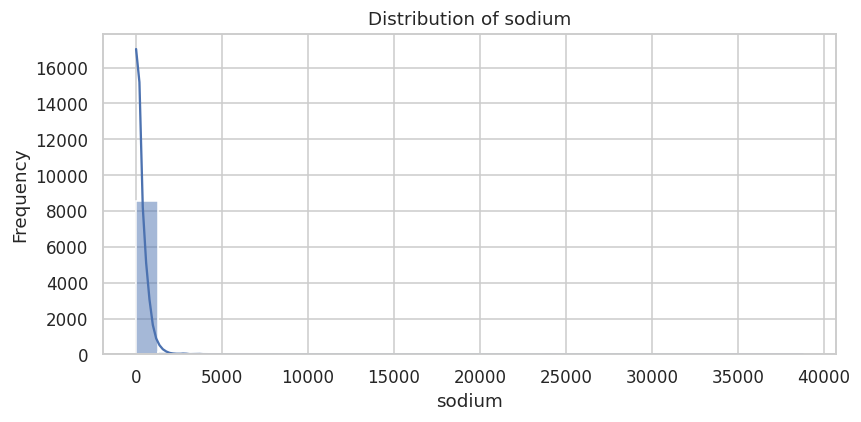

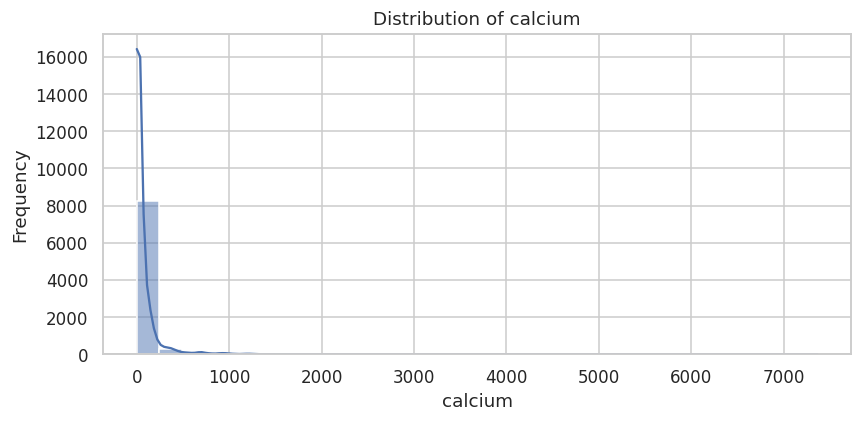

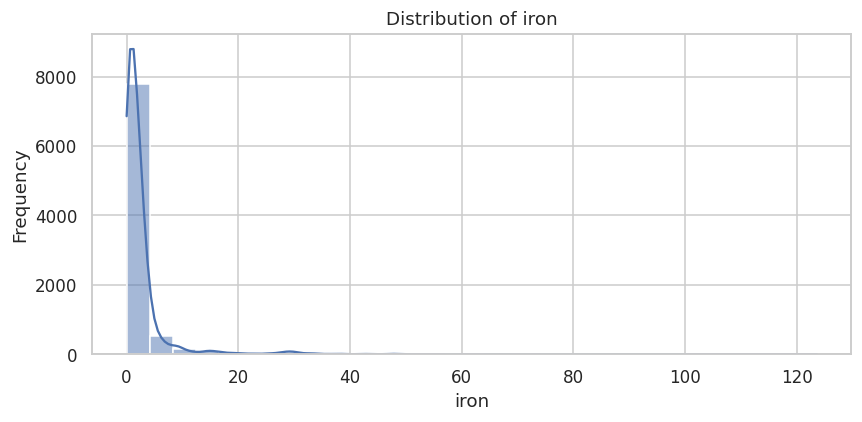

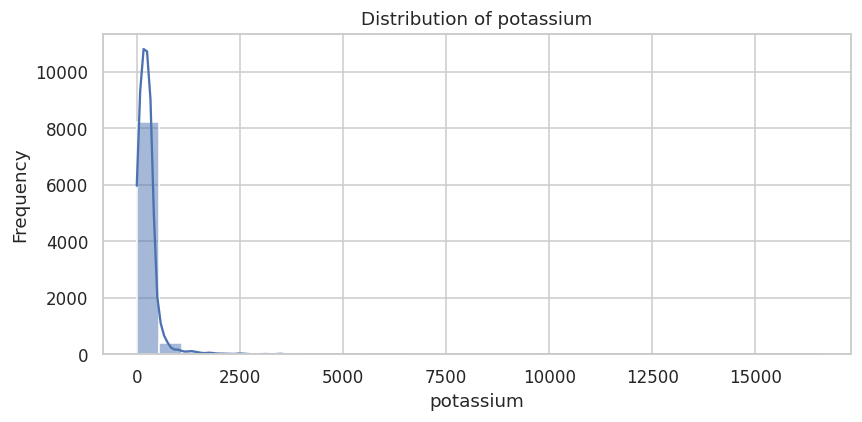

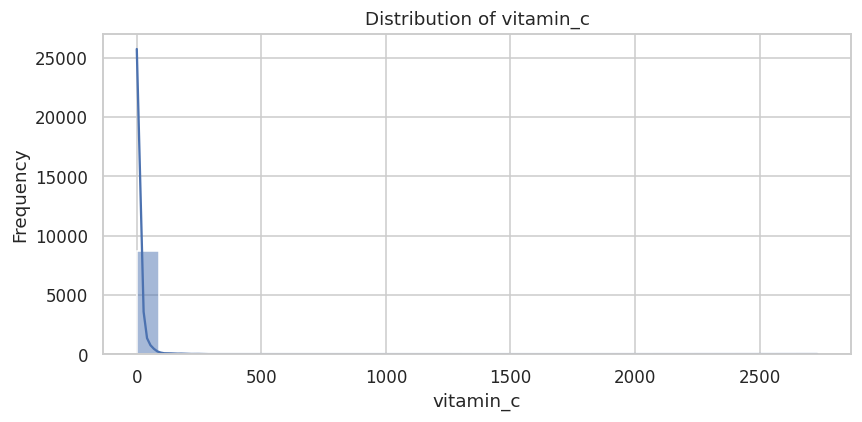

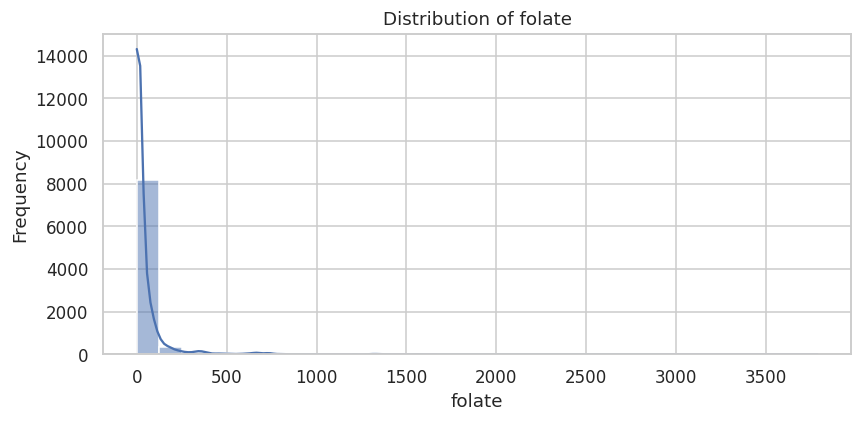

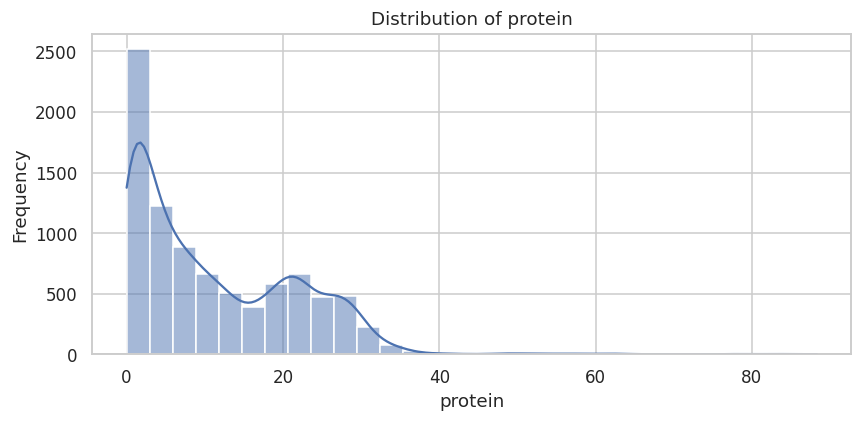

In [9]:
for col in numeric_df.columns:
    values = numeric_df[col].dropna()
    if values.empty:
        continue
    plt.figure(figsize=(8, 4))
    sns.histplot(values, bins=30, kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

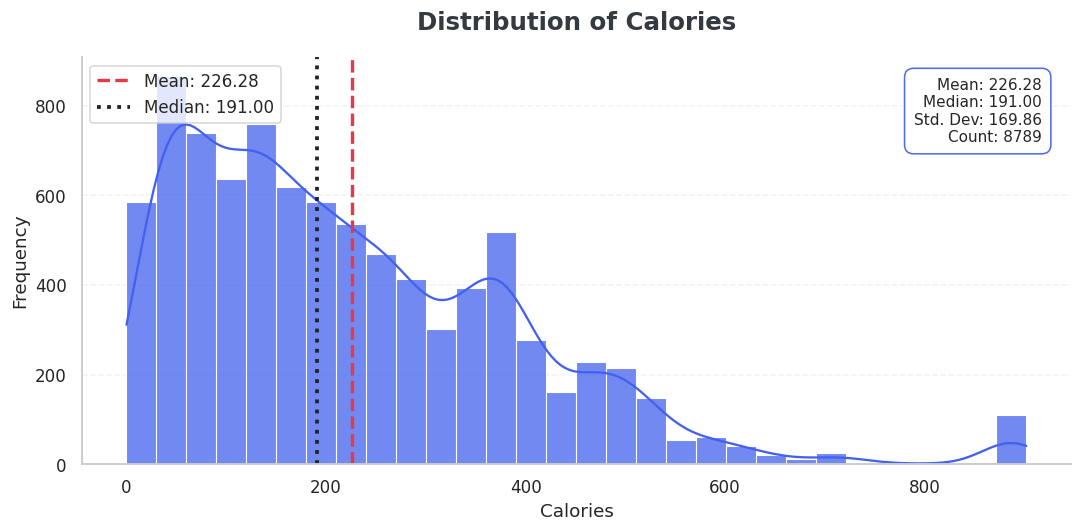

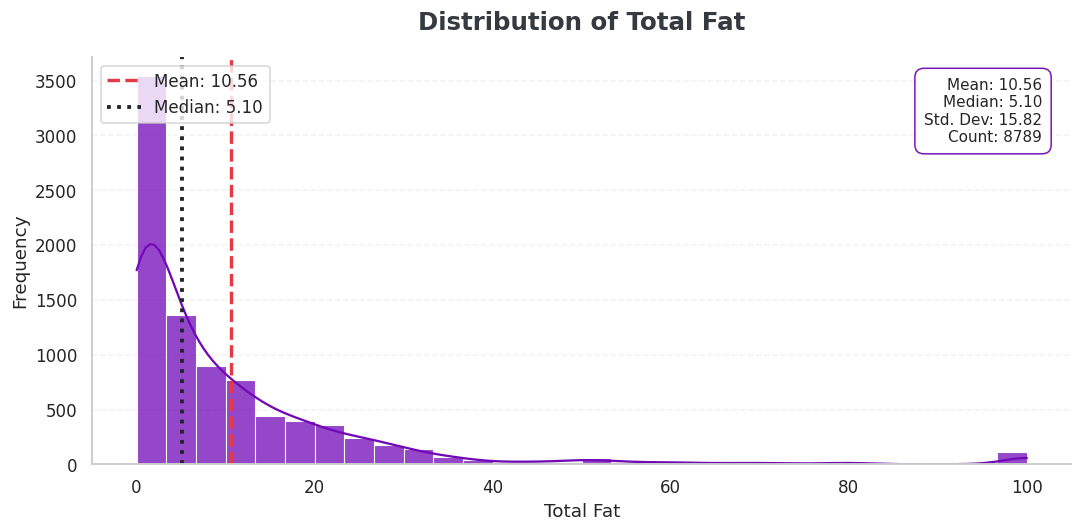

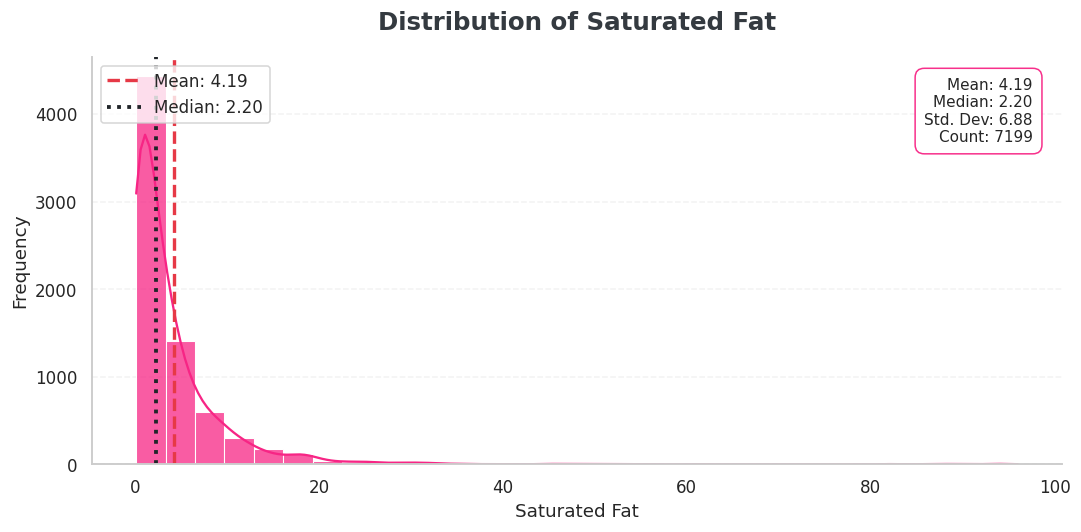

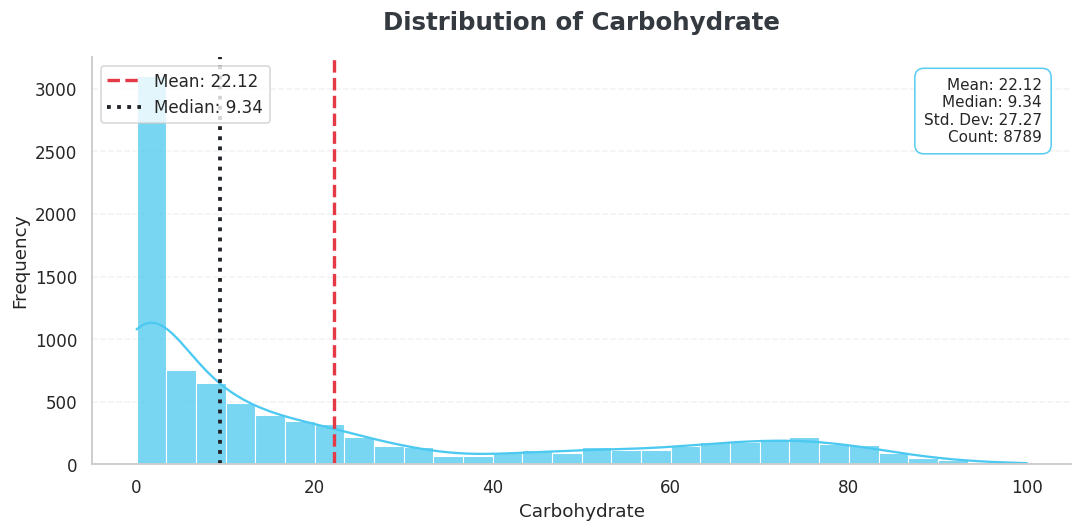

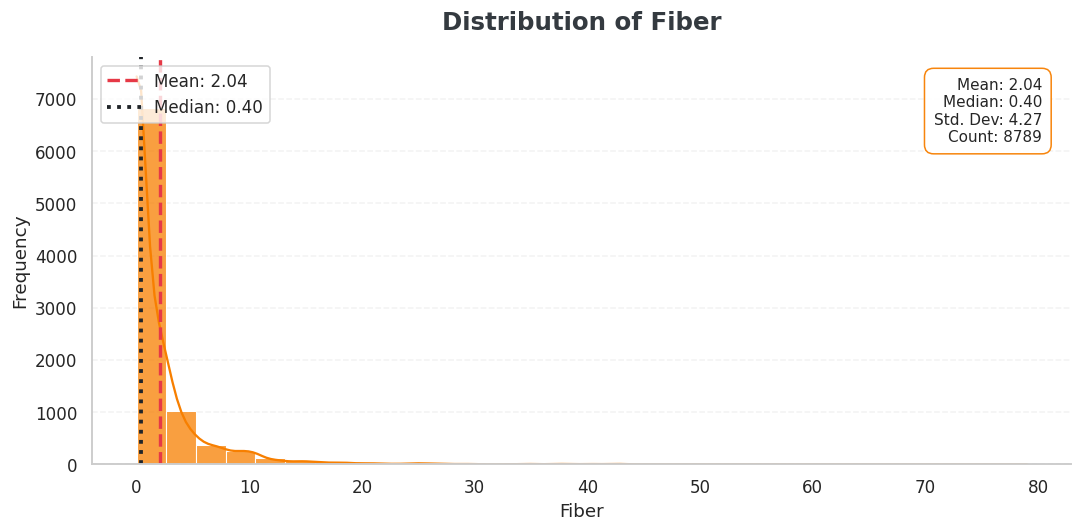

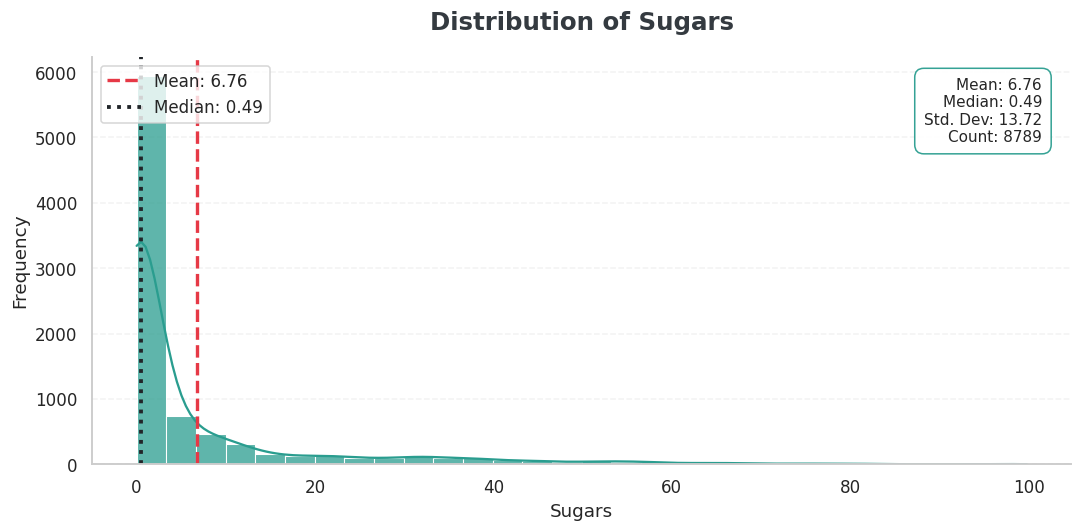

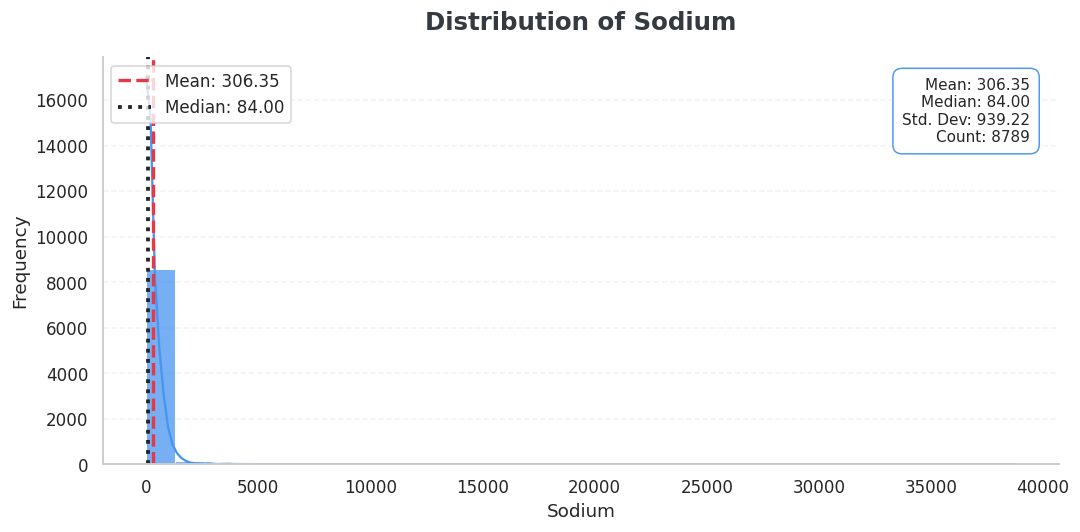

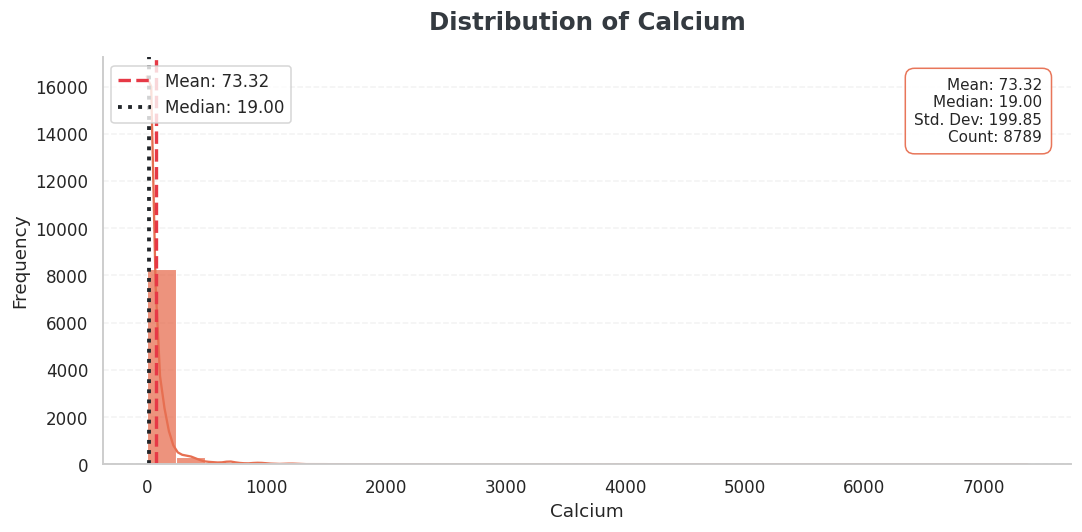

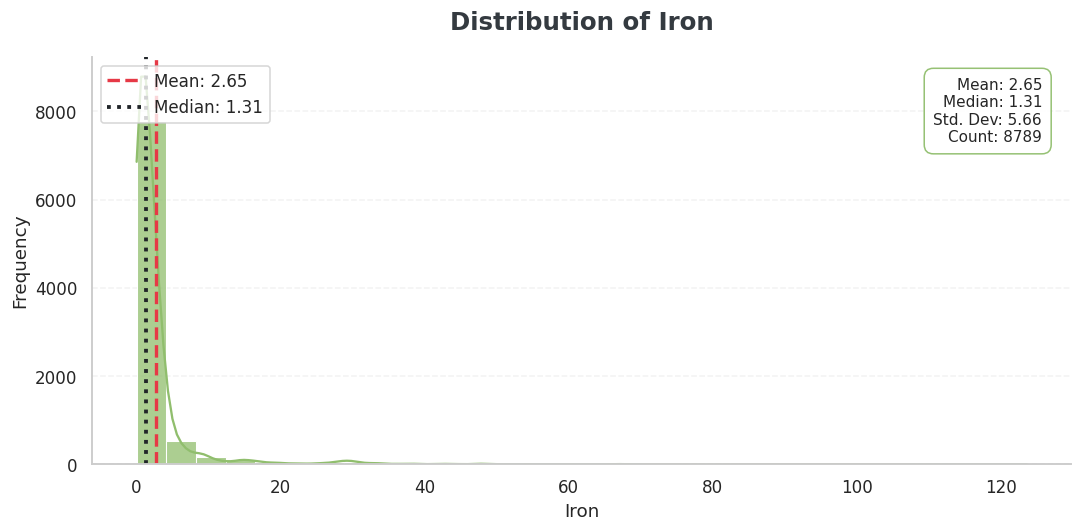

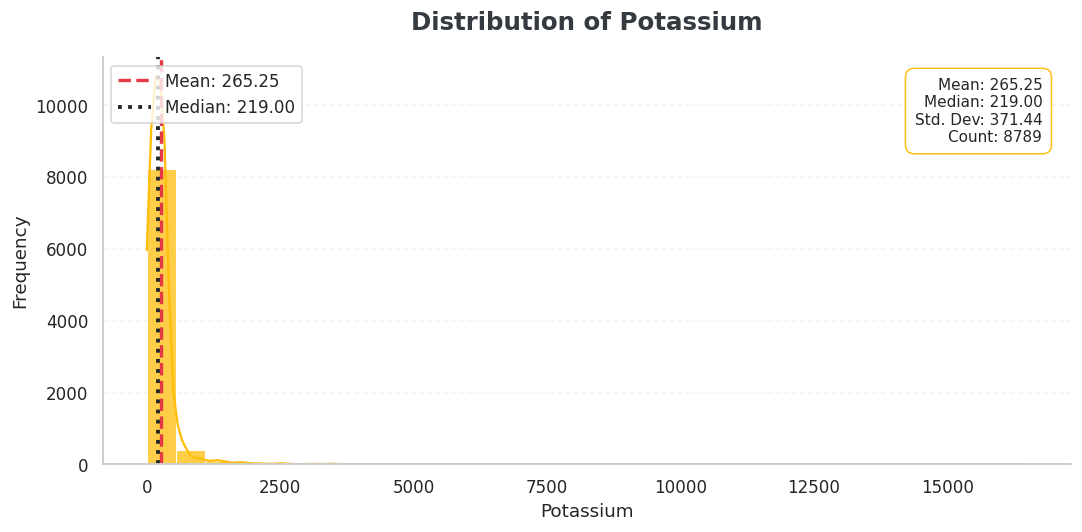

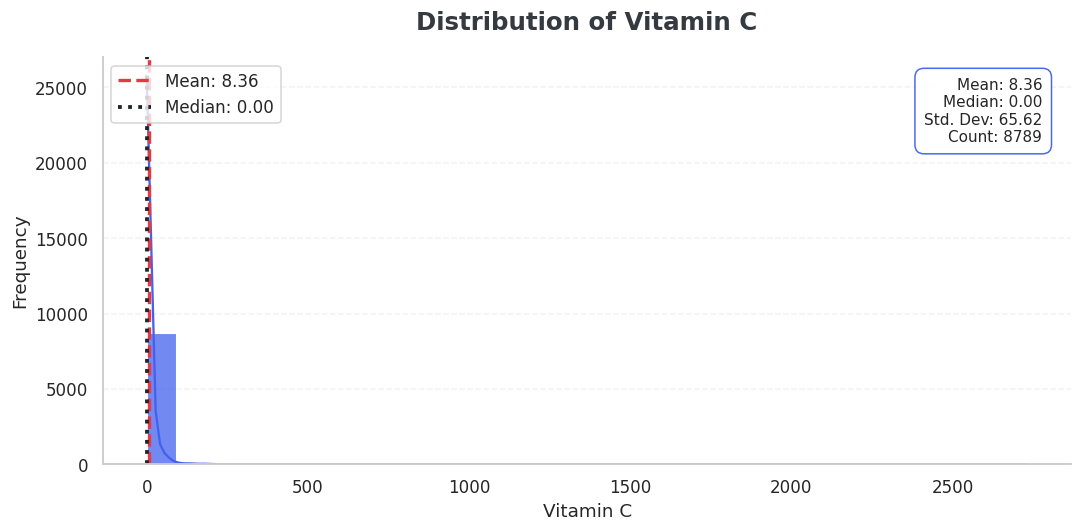

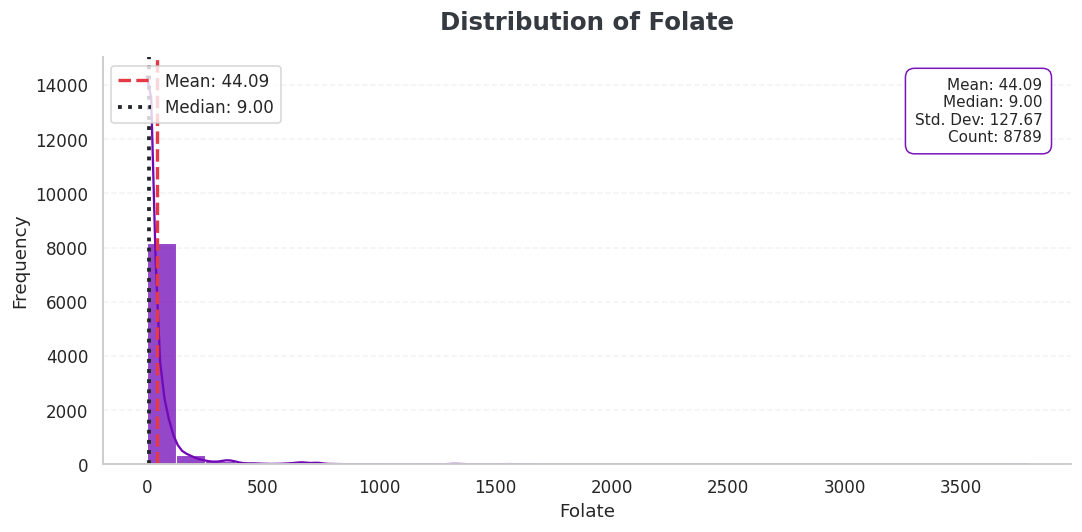

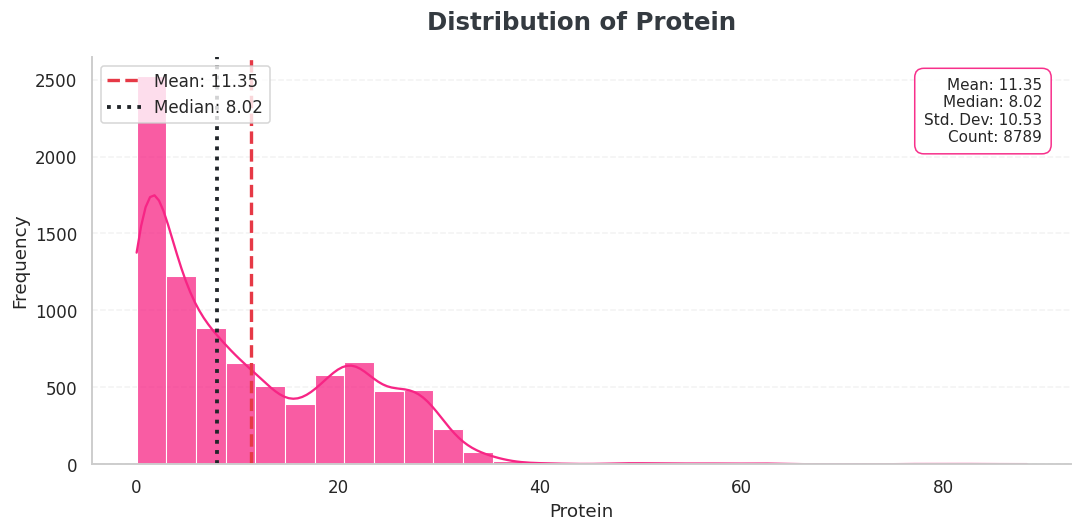

In [23]:
# ==========================================
# DISTRIBUTION ANALYSIS - HISTOGRAMS
# ==========================================

hist_colors = [
    "#4361EE",
    "#7209B7",
    "#F72585",
    "#4CC9F0",
    "#F77F00",
    "#2A9D8F",
    "#4895EF",
    "#E76F51",
    "#90BE6D",
    "#FFBE0B"
]

for i, col in enumerate(numeric_df.columns):

    values = numeric_df[col].dropna()

    if values.empty:
        continue

    mean_value = values.mean()
    median_value = values.median()

    fig, ax = plt.subplots(figsize=(10, 5))

    # Histogram with KDE
    sns.histplot(
        values,
        bins=30,
        kde=True,
        color=hist_colors[i % len(hist_colors)],
        edgecolor="white",
        linewidth=0.7,
        alpha=0.75,
        ax=ax
    )

    # Mean line
    ax.axvline(
        mean_value,
        color="#E63946",
        linestyle="--",
        linewidth=2.2,
        label=f"Mean: {mean_value:.2f}"
    )

    # Median line
    ax.axvline(
        median_value,
        color="#212529",
        linestyle=":",
        linewidth=2.5,
        label=f"Median: {median_value:.2f}"
    )

    # Statistics annotation
    stats_text = (
        f"Mean: {mean_value:.2f}\n"
        f"Median: {median_value:.2f}\n"
        f"Std. Dev: {values.std():.2f}\n"
        f"Count: {len(values)}"
    )

    ax.text(
        0.97,
        0.95,
        stats_text,
        transform=ax.transAxes,
        fontsize=10,
        verticalalignment="top",
        horizontalalignment="right",
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor="white",
            edgecolor=hist_colors[i % len(hist_colors)],
            alpha=0.95
        )
    )

    # Formatting
    ax.set_title(
        f"Distribution of {col.replace('_', ' ').title()}",
        fontsize=16,
        fontweight="bold",
        color="#343A40",
        pad=18
    )

    ax.set_xlabel(
        col.replace("_", " ").title(),
        fontsize=12
    )

    ax.set_ylabel(
        "Frequency",
        fontsize=12
    )

    ax.legend(
        loc="upper left",
        frameon=True
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.grid(axis="x", visible=False)

    sns.despine()

    plt.tight_layout()
    plt.show()

## 10. Boxplots — numerical attributes and potential outliers

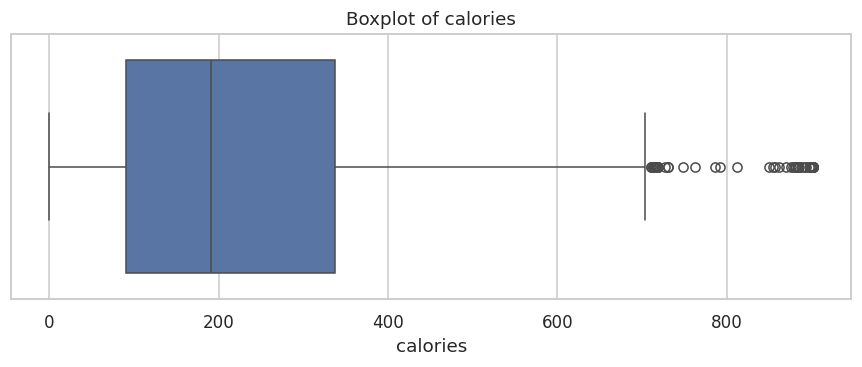

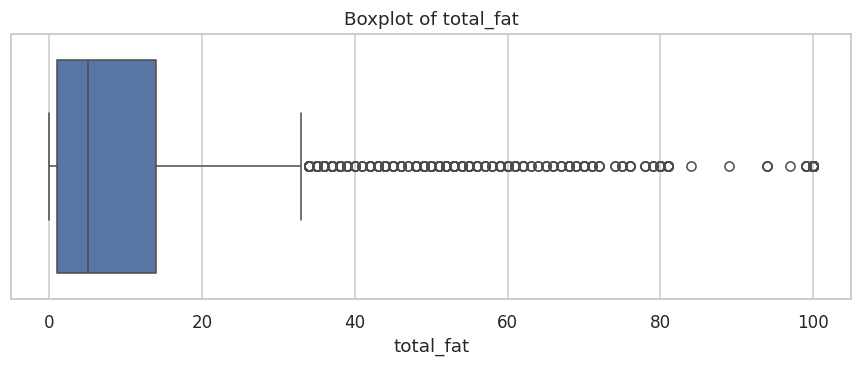

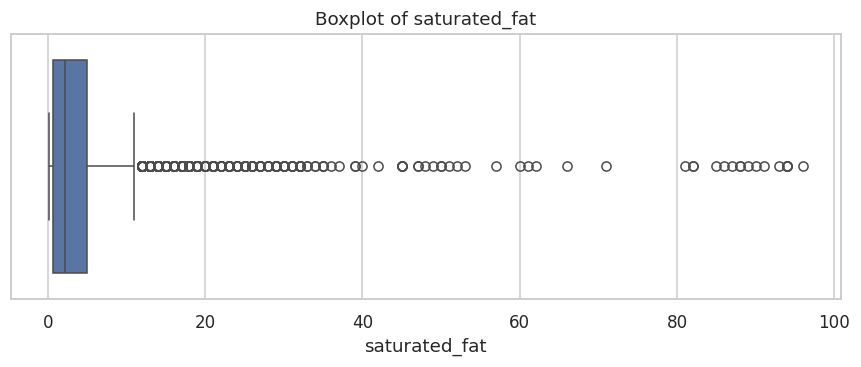

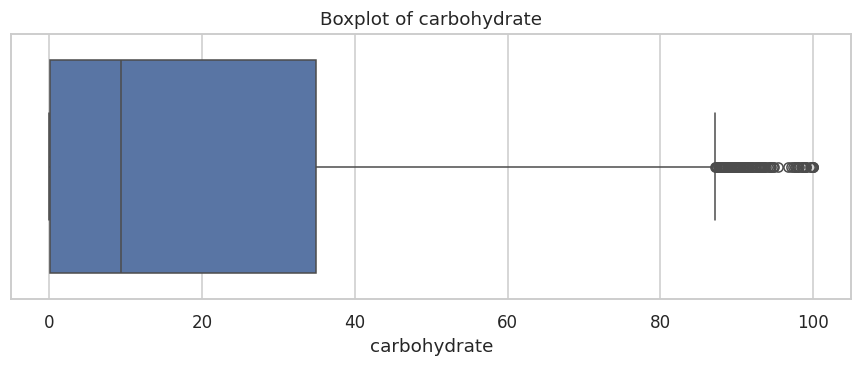

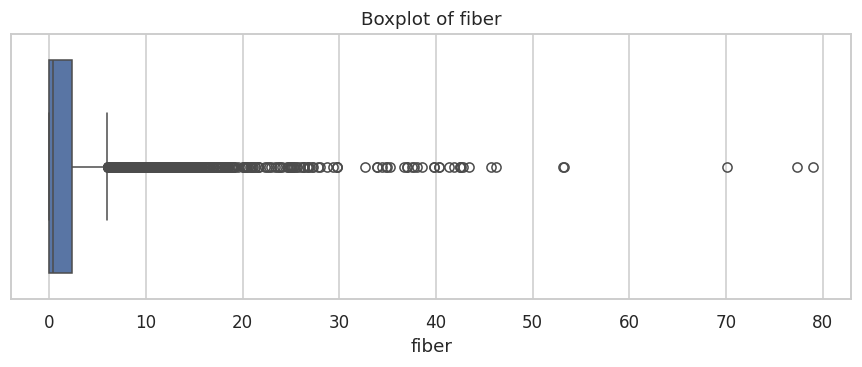

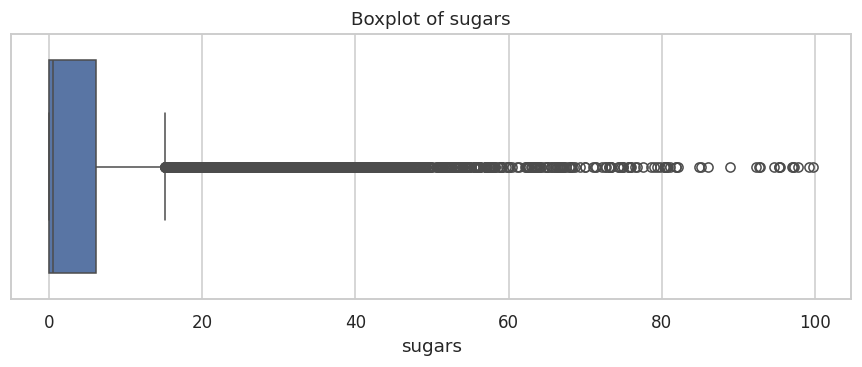

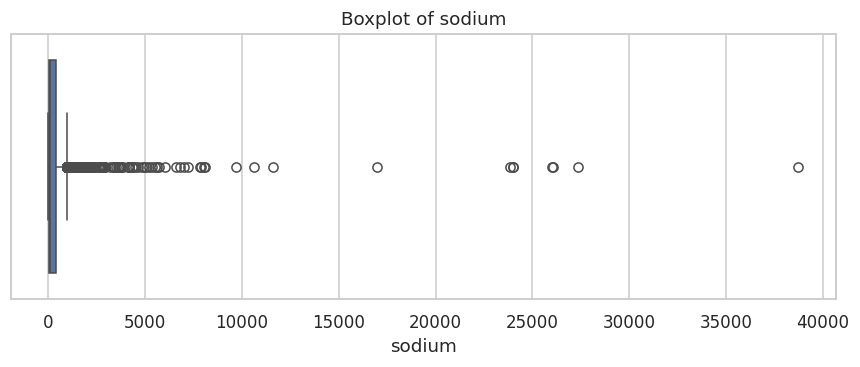

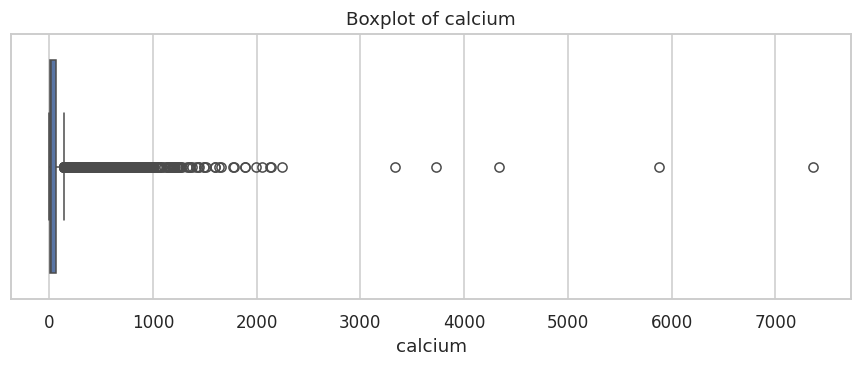

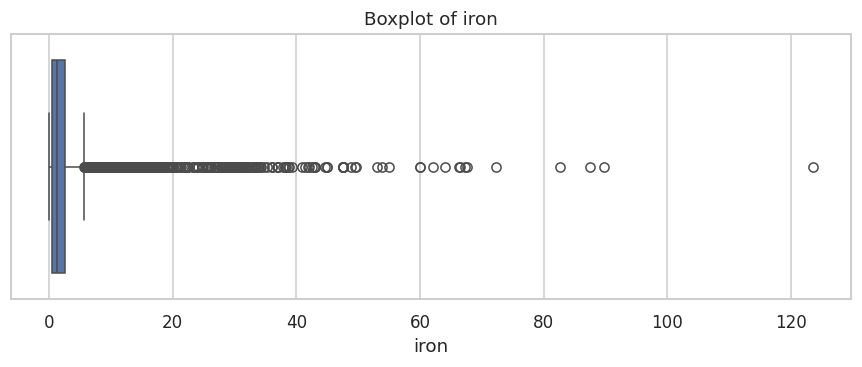

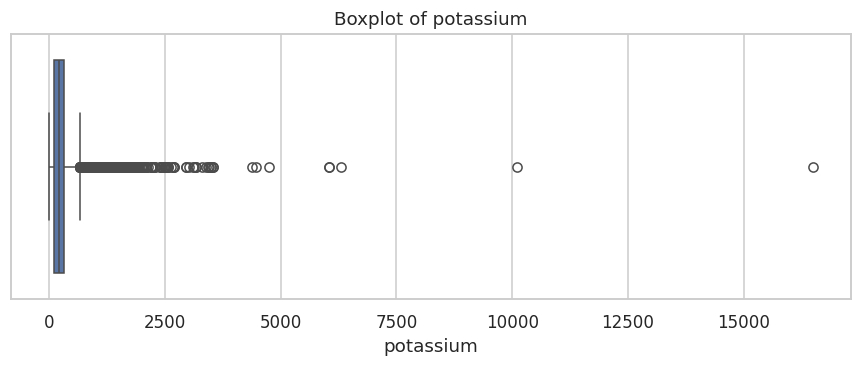

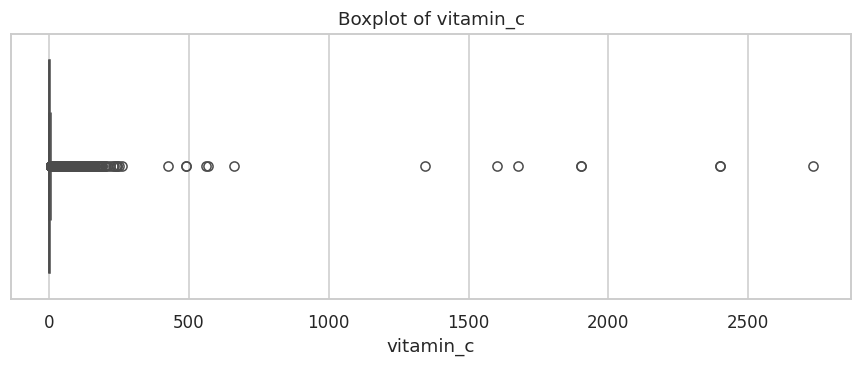

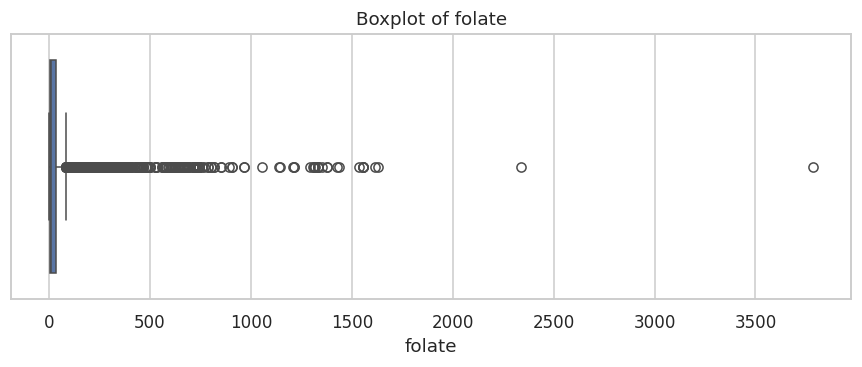

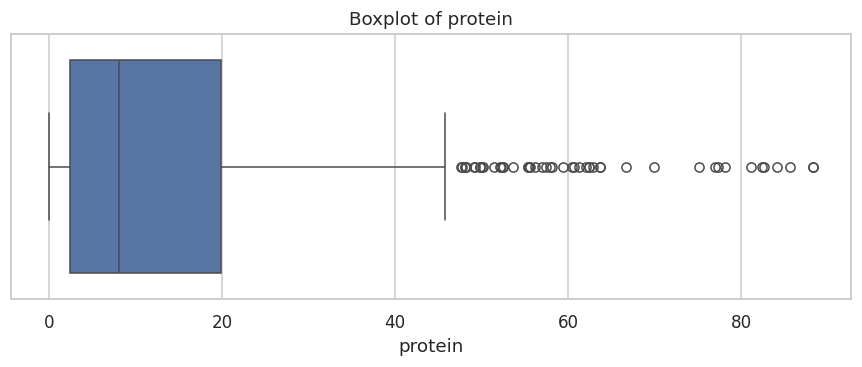

In [10]:
for col in numeric_df.columns:
    values = numeric_df[col].dropna()
    if values.empty:
        continue
    plt.figure(figsize=(8, 3.5))
    sns.boxplot(x=values)
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

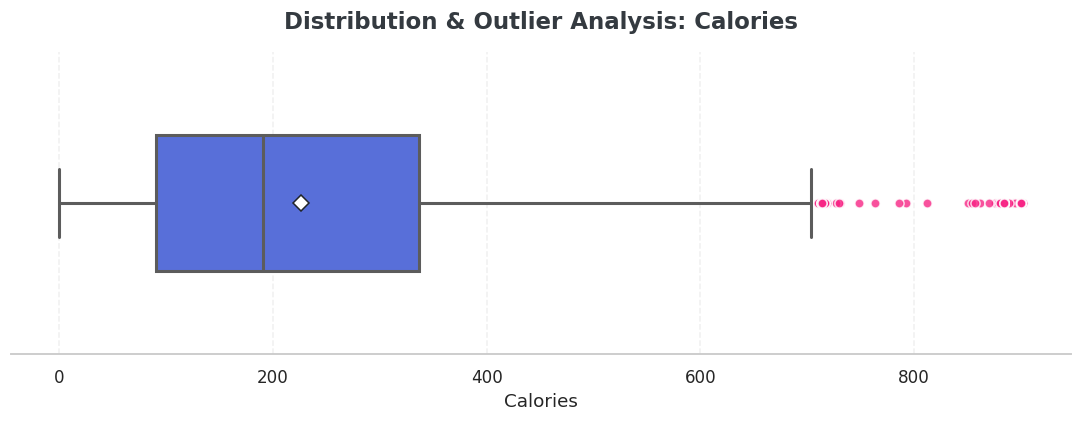

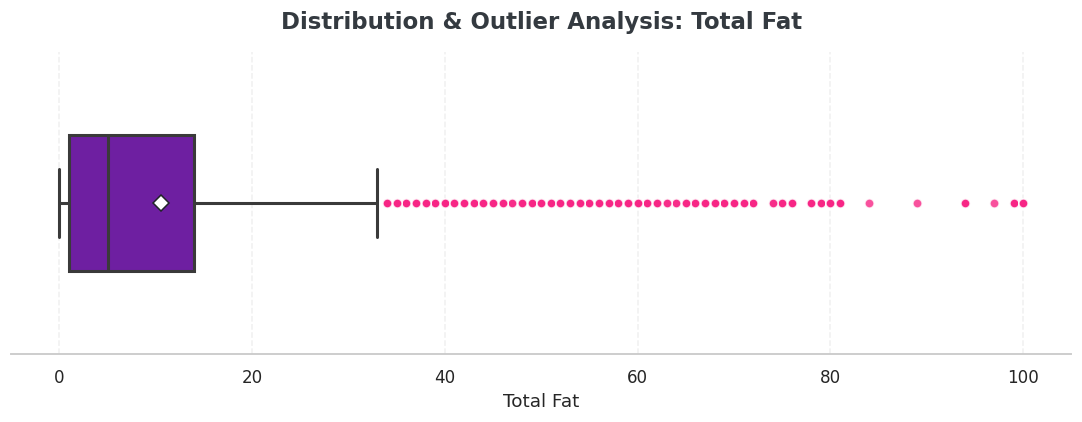

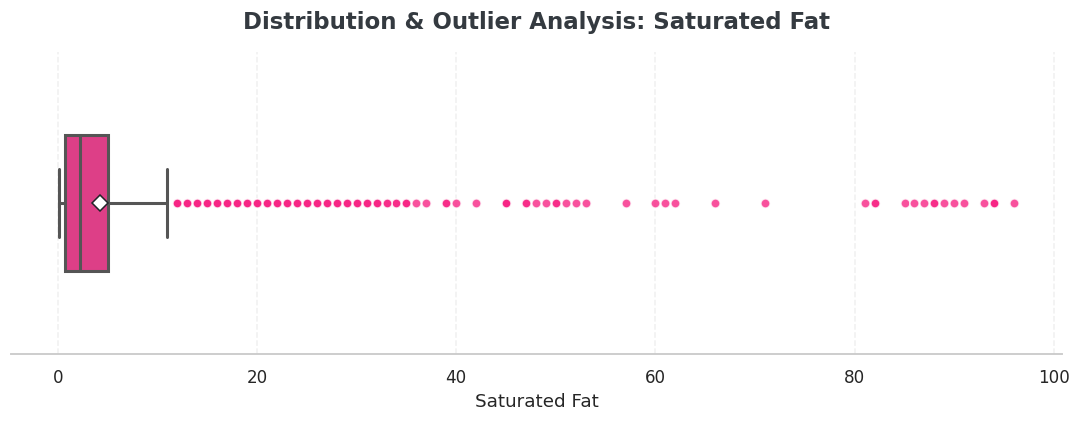

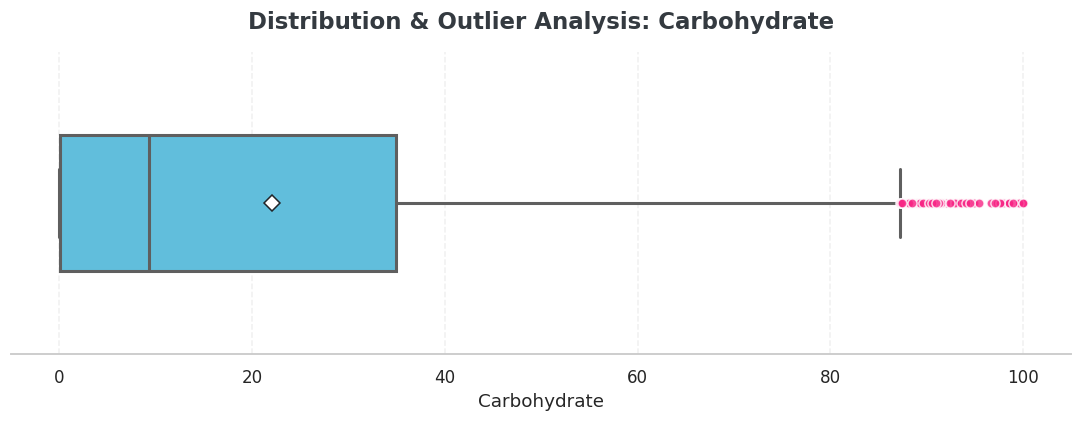

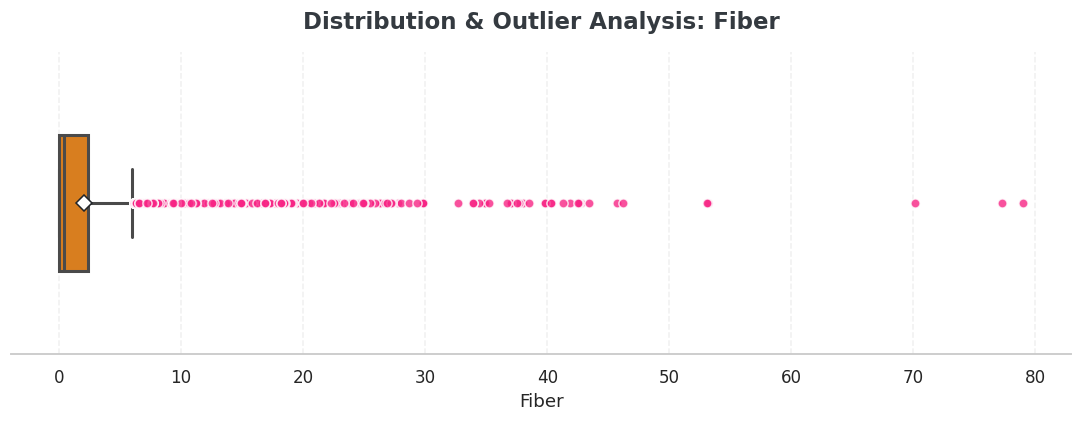

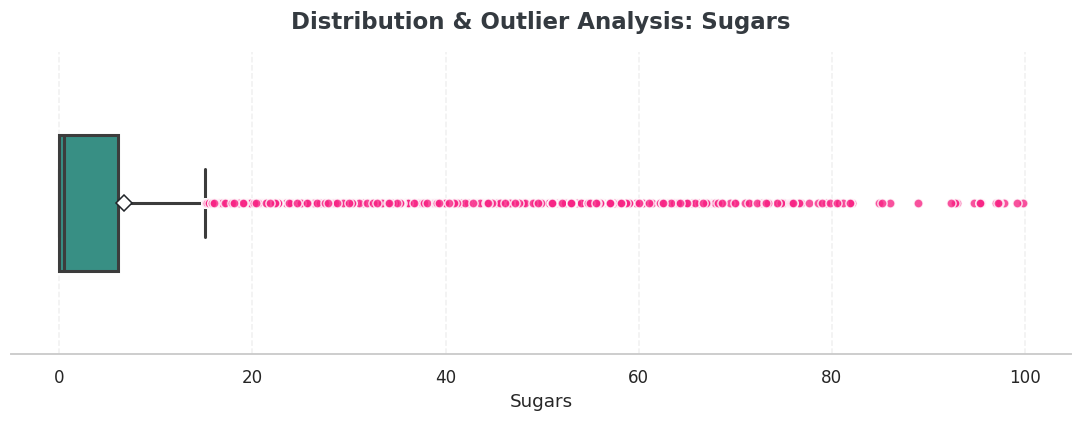

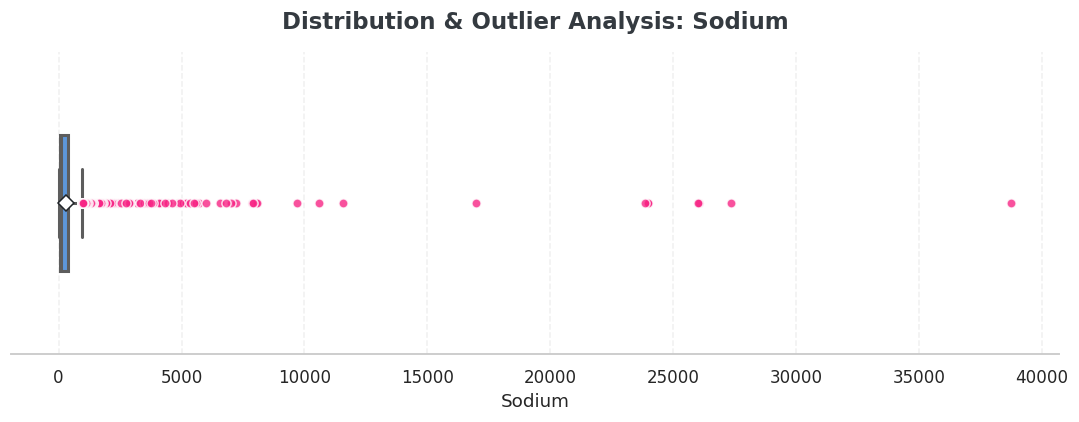

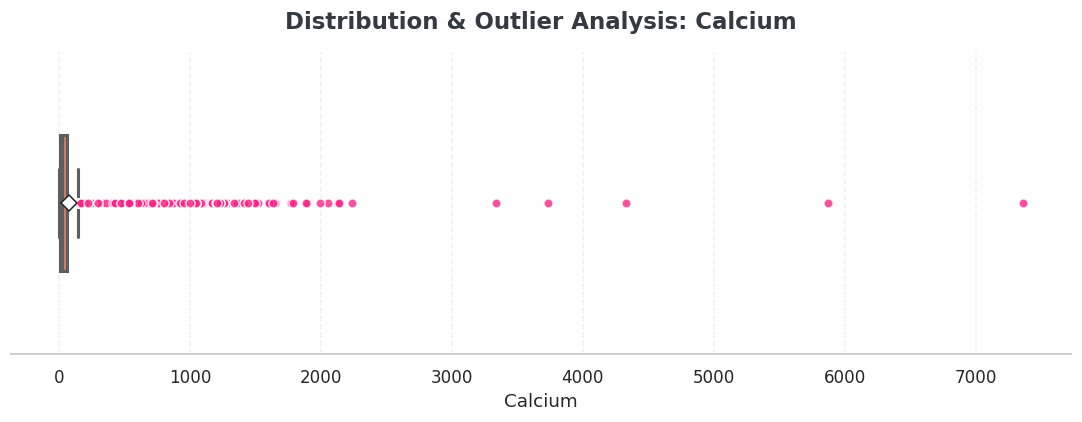

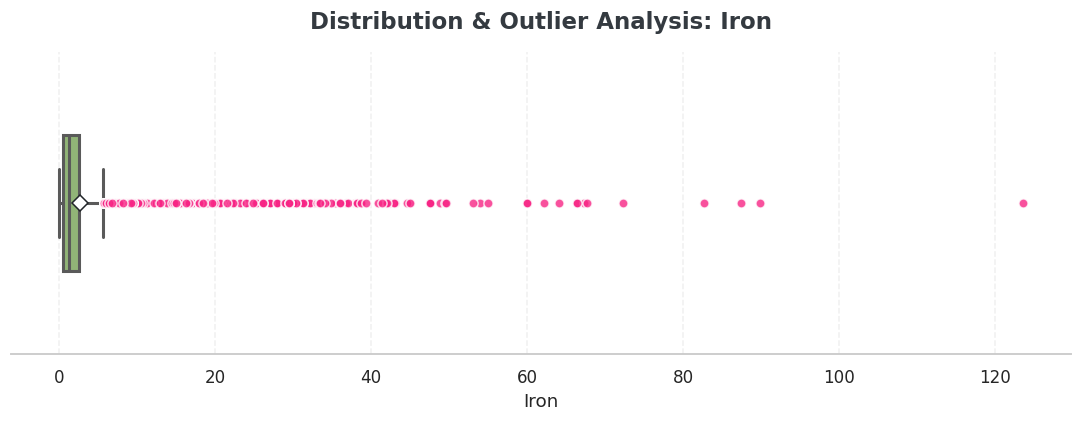

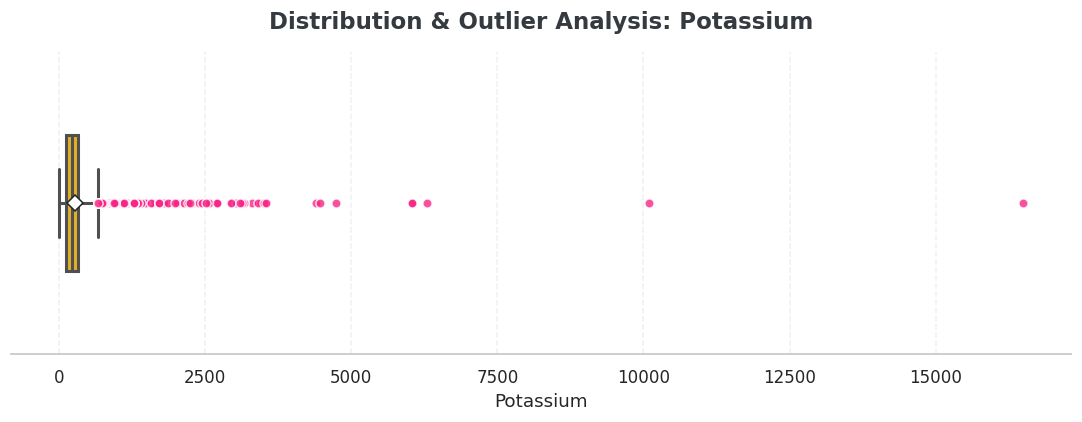

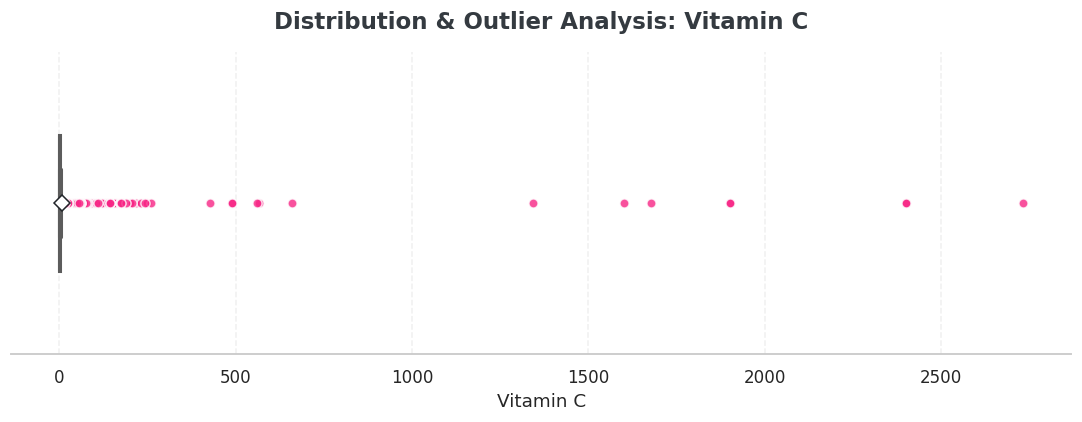

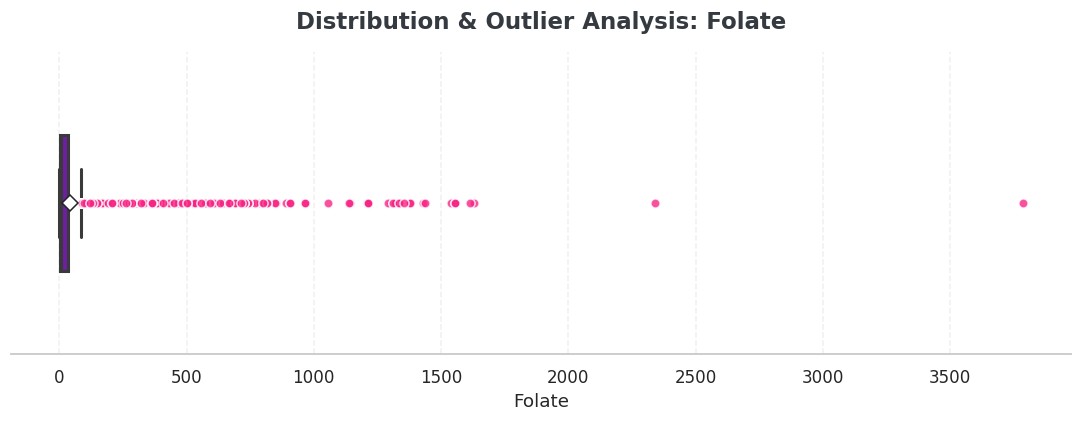

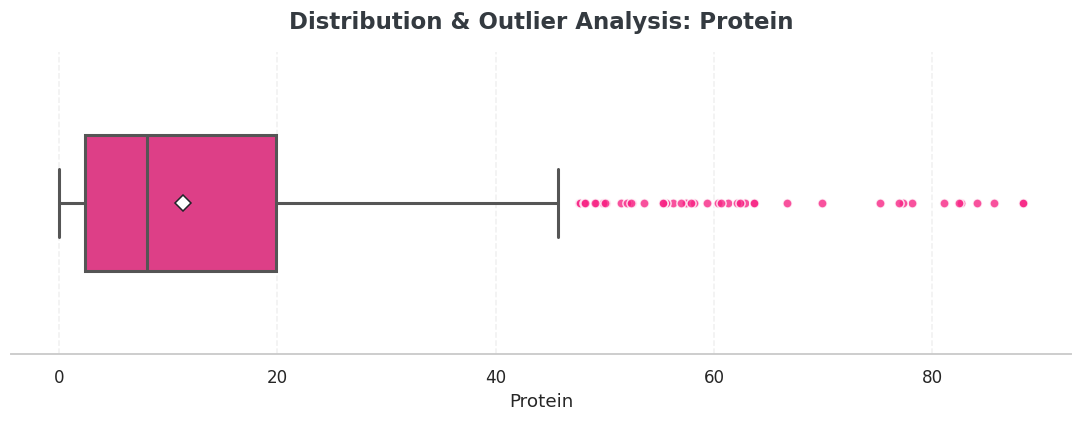

In [22]:
# ==========================================
# BOXPLOT ANALYSIS OF NUMERICAL ATTRIBUTES
# ==========================================

box_colors = [
    "#4361EE",
    "#7209B7",
    "#F72585",
    "#4CC9F0",
    "#F77F00",
    "#2A9D8F",
    "#4895EF",
    "#E76F51",
    "#90BE6D",
    "#FFBE0B"
]

for i, col in enumerate(numeric_df.columns):

    values = numeric_df[col].dropna()

    if values.empty:
        continue

    fig, ax = plt.subplots(figsize=(10, 4))

    sns.boxplot(
        x=values,
        color=box_colors[i % len(box_colors)],
        width=0.45,
        linewidth=2,
        showmeans=True,
        meanprops={
            "marker": "D",
            "markerfacecolor": "#FFFFFF",
            "markeredgecolor": "#212529",
            "markersize": 7
        },
        flierprops={
            "marker": "o",
            "markerfacecolor": "#F72585",
            "markeredgecolor": "#FFFFFF",
            "markersize": 6,
            "alpha": 0.8
        },
        ax=ax
    )

    # Median line
    ax.set_title(
        f"Distribution & Outlier Analysis: {col.replace('_', ' ').title()}",
        fontsize=15,
        fontweight="bold",
        color="#343A40",
        pad=15
    )

    ax.set_xlabel(
        col.replace("_", " ").title(),
        fontsize=12
    )

    ax.set_ylabel("")

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.3
    )

    ax.grid(axis="y", visible=False)

    sns.despine(
        left=True,
        top=True,
        right=True
    )

    plt.tight_layout()
    plt.show()

## 11. IQR-based outlier detection

In [11]:
outlier_rows = []

for col in numeric_df.columns:
    series = numeric_df[col].dropna()
    if series.empty:
        continue
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_count = ((series < lower_bound) | (series > upper_bound)).sum()
    outlier_rows.append({
        "Attribute": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count,
        "Outlier Percentage (%)": 100 * outlier_count / len(series)
    })

outlier_summary = pd.DataFrame(outlier_rows).sort_values("Outlier Count", ascending=False)
display(outlier_summary.round(3))

print("Note: IQR flags statistical extremes, not automatically incorrect values.")
print("Nutrient-rich foods can legitimately have high values.")

,Attribute,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage (%)
10,vitamin_c,0.00,2.40,2.40,-3.600,6.000,1631,18.557
5,sugars,0.00,6.05,6.05,-9.075,15.125,1230,13.995
11,folate,2.00,35.00,33.00,-47.500,84.500,1016,11.560
7,calcium,8.00,63.00,55.00,-74.500,145.500,992,11.287
4,fiber,0.00,2.40,2.40,-3.600,6.000,805,9.159
8,iron,0.49,2.57,2.08,-2.630,5.690,687,7.817
2,saturated_fat,0.70,5.00,4.30,-5.750,11.450,535,7.432
1,total_fat,1.00,14.00,13.00,-18.500,33.500,475,5.404
6,sodium,36.00,396.00,360.00,-504.000,936.000,473,5.382
9,potassium,111.00,329.00,218.00,-216.000,656.000,378,4.301


Note: IQR flags statistical extremes, not automatically incorrect values.
Nutrient-rich foods can legitimately have high values.


## 12. Serving-size analysis

Serving-size values:


,Count
serving_size,
100 g,8789


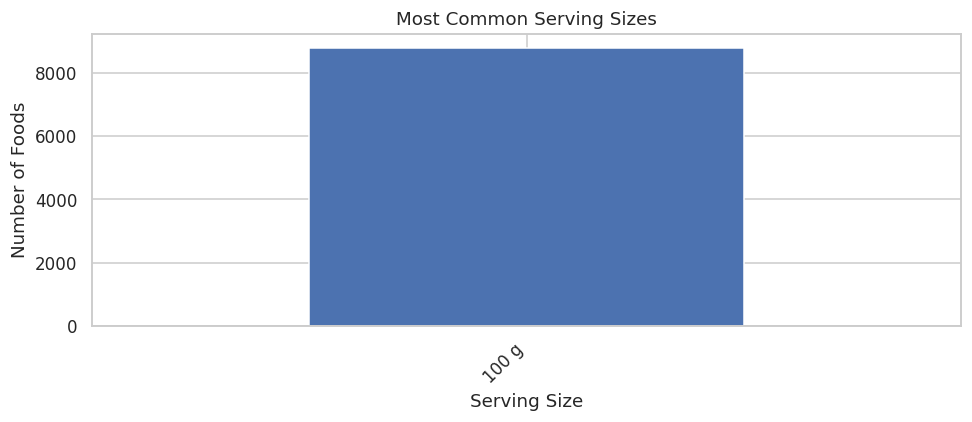

In [12]:
if "serving_size" in df_eda.columns:
    print("Serving-size values:")
    display(df_eda["serving_size"].value_counts(dropna=False).head(20).to_frame("Count"))

    plt.figure(figsize=(9, 4))
    df_eda["serving_size"].value_counts().head(15).plot(kind="bar")
    plt.title("Most Common Serving Sizes")
    plt.xlabel("Serving Size")
    plt.ylabel("Number of Foods")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

## 13. Correlation analysis

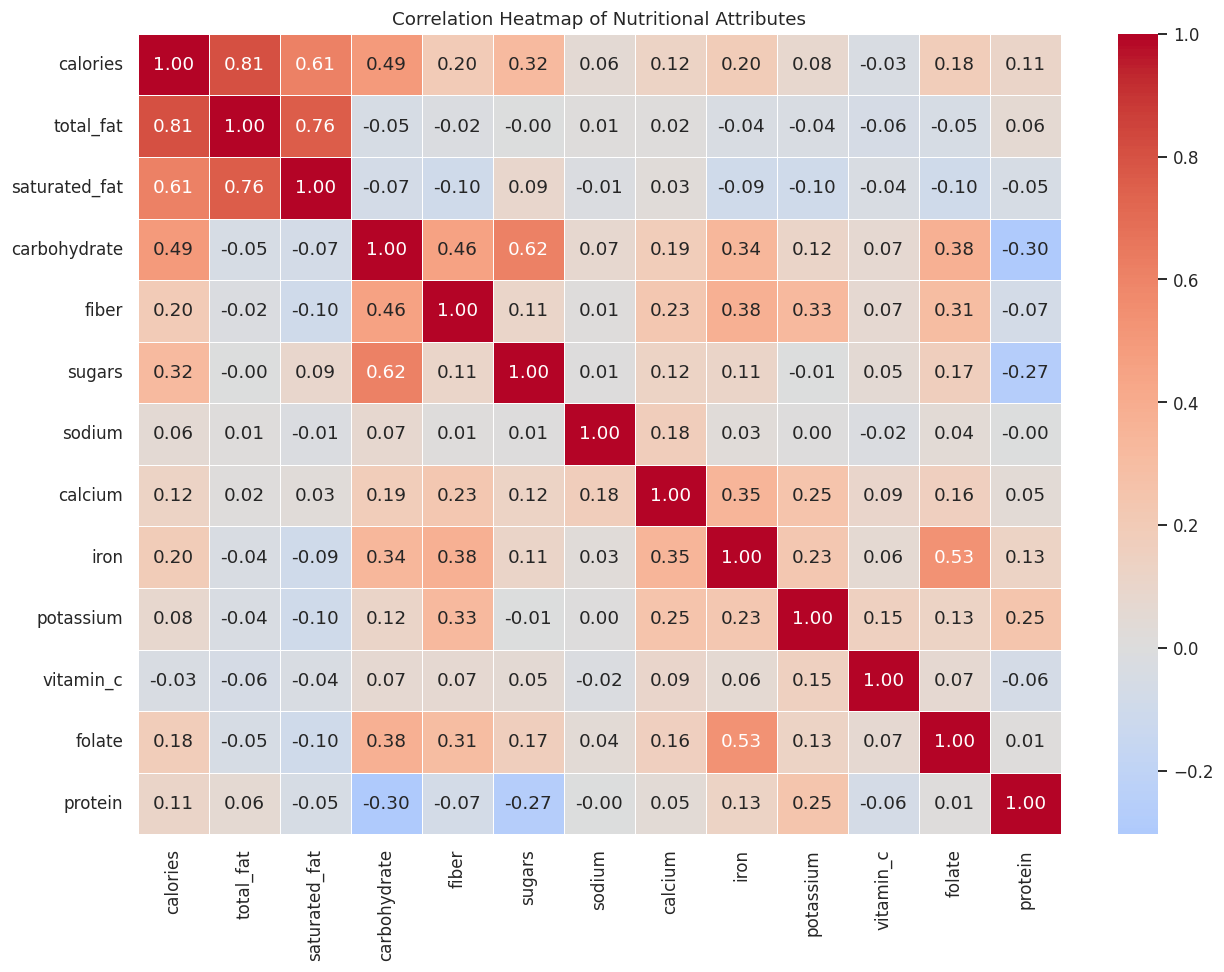

Strongest absolute correlations (excluding self-correlations):


,,Correlation
calories,total_fat,0.806574
total_fat,saturated_fat,0.759576
carbohydrate,sugars,0.616656
calories,saturated_fat,0.613212
iron,folate,0.531806
calories,carbohydrate,0.492915
carbohydrate,fiber,0.455886
fiber,iron,0.381205
carbohydrate,folate,0.379688
calcium,iron,0.351724


In [13]:
corr = numeric_df.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Nutritional Attributes")
plt.tight_layout()
plt.show()

print("Strongest absolute correlations (excluding self-correlations):")
corr_pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
display(corr_pairs.reindex(corr_pairs.abs().sort_values(ascending=False).index).head(15).to_frame("Correlation"))

## 14. Bivariate analysis — calories versus nutrients

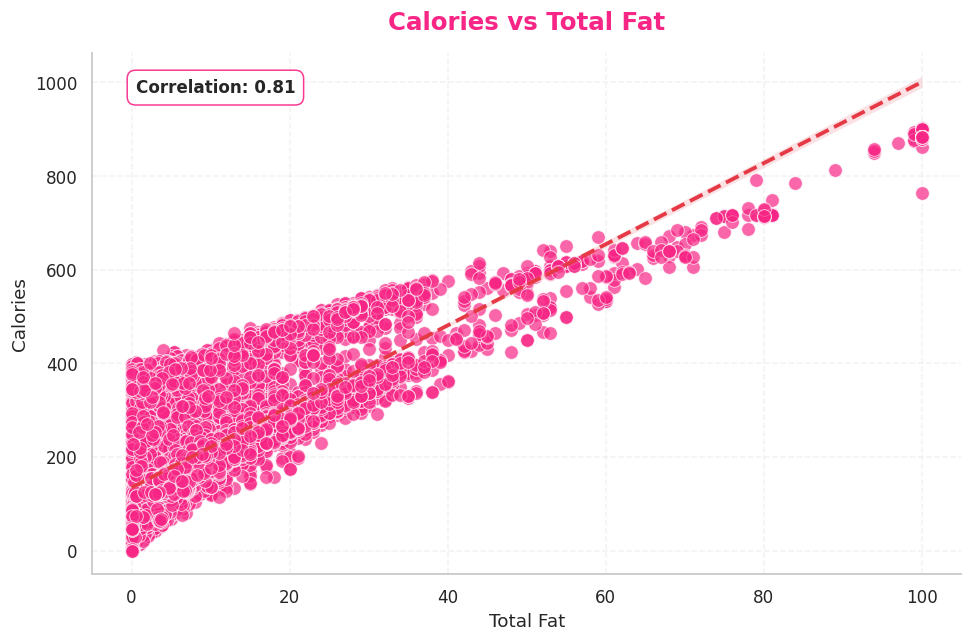

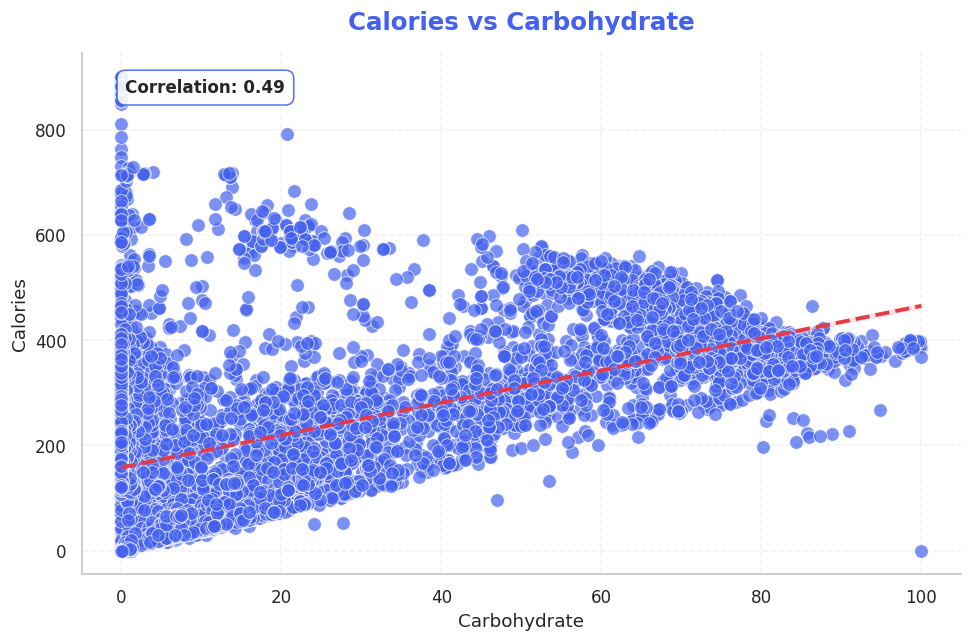

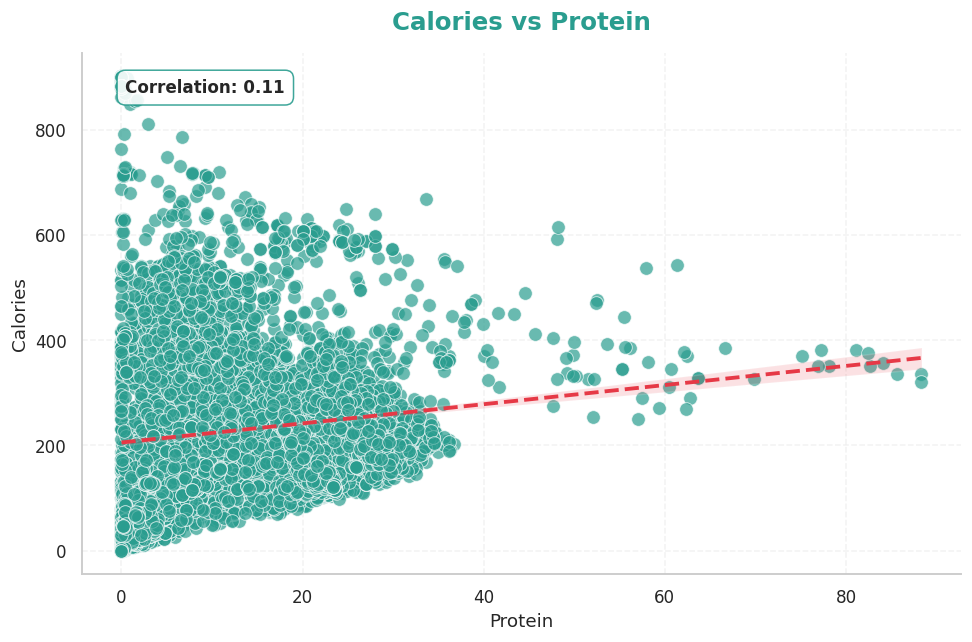

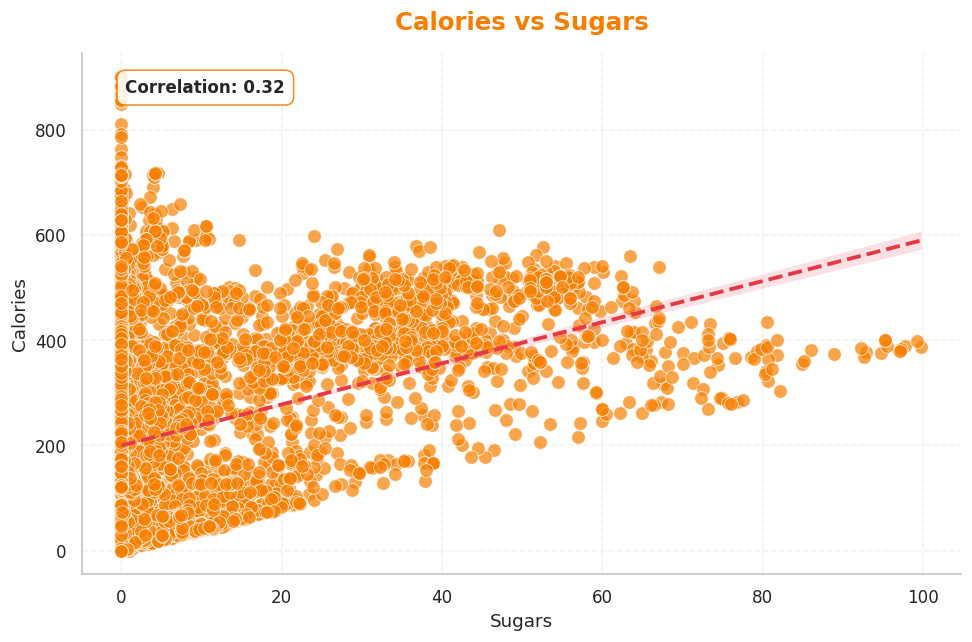

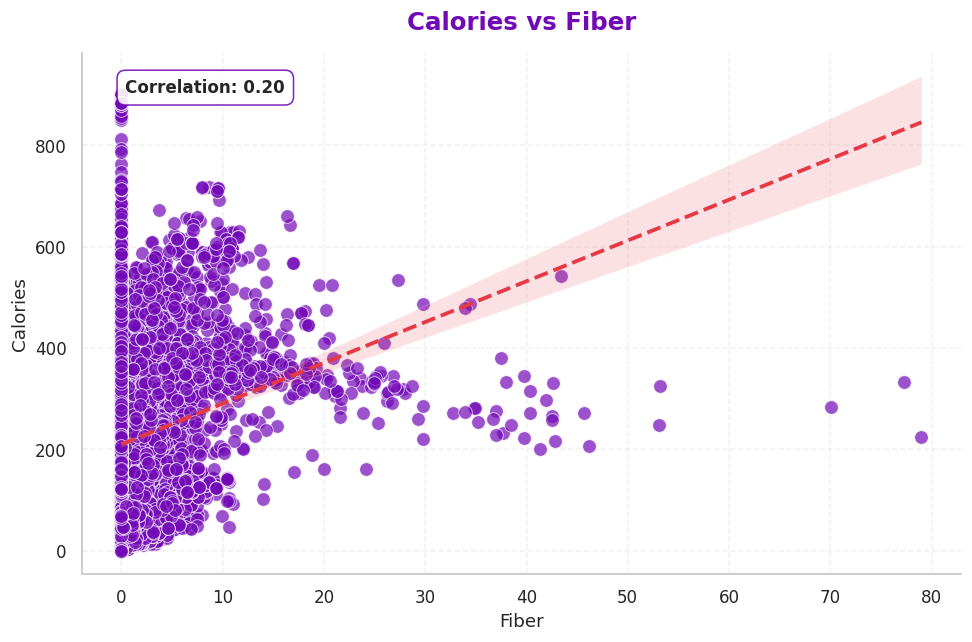

In [19]:
# ==========================================
# BIVARIATE ANALYSIS: CALORIES VS NUTRIENTS
# ==========================================

relationship_cols = [
    col for col in ["total_fat", "carbohydrate", "protein", "sugars", "fiber"]
    if col in numeric_df.columns
]

colors = ["#F72585", "#4361EE", "#2A9D8F", "#F77F00", "#7209B7"]

for i, col in enumerate(relationship_cols):

    plot_df = (
        df_eda[["calories", col]]
        .dropna()
        if "calories" in df_eda.columns
        else pd.DataFrame()
    )

    if not plot_df.empty:

        correlation = plot_df[col].corr(plot_df["calories"])

        fig, ax = plt.subplots(figsize=(9, 6))

        # Scatter plot
        sns.scatterplot(
            data=plot_df,
            x=col,
            y="calories",
            color=colors[i],
            s=80,
            alpha=0.7,
            edgecolor="white",
            linewidth=0.6,
            ax=ax
        )

        # Trend line
        sns.regplot(
            data=plot_df,
            x=col,
            y="calories",
            scatter=False,
            color="#E63946",
            line_kws={
                "linewidth": 2.5,
                "linestyle": "--"
            },
            ax=ax
        )

        # Correlation annotation
        ax.text(
            0.05,
            0.95,
            f"Correlation: {correlation:.2f}",
            transform=ax.transAxes,
            fontsize=11,
            fontweight="bold",
            verticalalignment="top",
            bbox=dict(
                boxstyle="round,pad=0.5",
                facecolor="white",
                edgecolor=colors[i],
                alpha=0.9
            )
        )

        # Formatting
        ax.set_title(
            f"Calories vs {col.replace('_', ' ').title()}",
            fontsize=16,
            fontweight="bold",
            color=colors[i],
            pad=15
        )

        ax.set_xlabel(
            col.replace("_", " ").title(),
            fontsize=12
        )

        ax.set_ylabel(
            "Calories",
            fontsize=12
        )

        ax.grid(
            True,
            linestyle="--",
            alpha=0.25
        )

        sns.despine()

        plt.tight_layout()
        plt.show()

## 15. Compare foods by selected nutrients

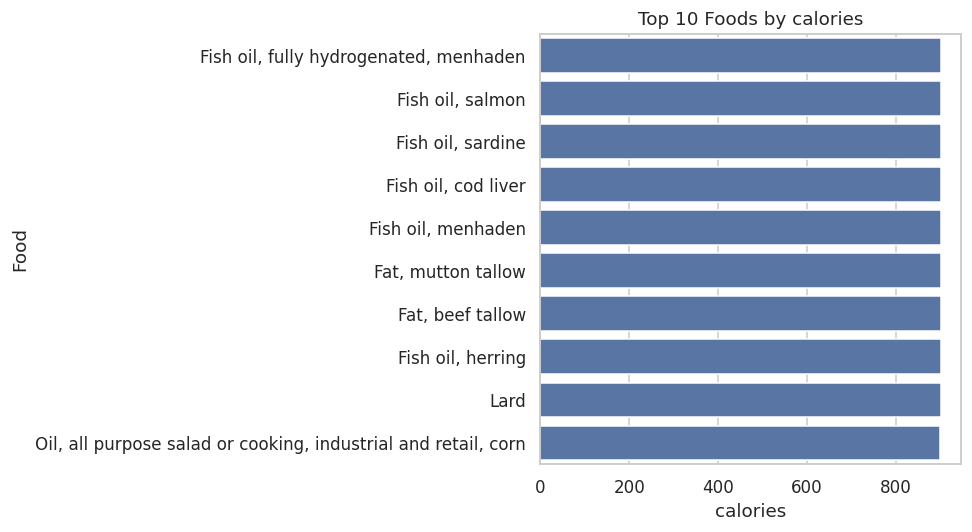

,Food Name,calories
2253,"Fish oil, fully hydrogenated, menhaden",902
422,"Fish oil, salmon",902
355,"Fish oil, sardine",902
256,"Fish oil, cod liver",902
293,"Fish oil, menhaden",902
318,"Fat, mutton tallow",902
430,"Fat, beef tallow",902
356,"Fish oil, herring",902
676,Lard,902
5621,"Oil, all purpose salad or cooking, industrial ...",900


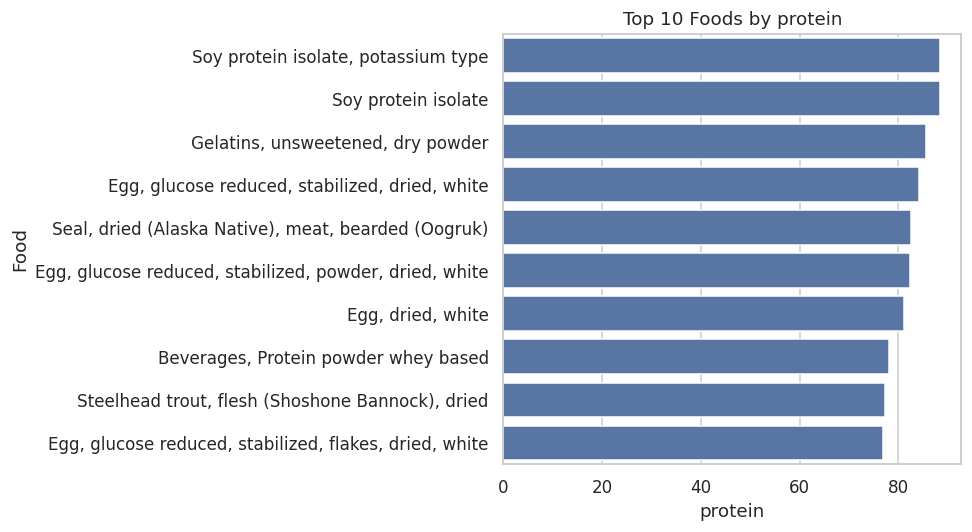

,Food Name,protein
1378,"Soy protein isolate, potassium type",88.32
213,Soy protein isolate,88.32
1618,"Gelatins, unsweetened, dry powder",85.60
3893,"Egg, glucose reduced, stabilized, dried, white",84.08
4401,"Seal, dried (Alaska Native), meat, bearded (Oo...",82.60
5357,"Egg, glucose reduced, stabilized, powder, drie...",82.40
389,"Egg, dried, white",81.10
2476,"Beverages, Protein powder whey based",78.13
3546,"Steelhead trout, flesh (Shoshone Bannock), dried",77.27
5356,"Egg, glucose reduced, stabilized, flakes, drie...",76.92


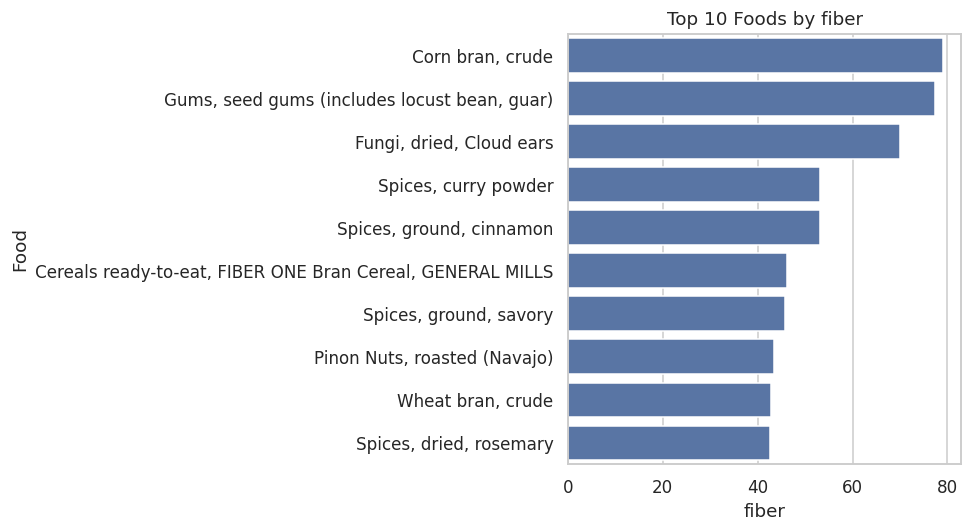

,Food Name,fiber
404,"Corn bran, crude",79.0
2829,"Gums, seed gums (includes locust bean, guar)",77.3
1170,"Fungi, dried, Cloud ears",70.1
183,"Spices, curry powder",53.2
1209,"Spices, ground, cinnamon",53.1
6114,"Cereals ready-to-eat, FIBER ONE Bran Cereal, G...",46.2
22,"Spices, ground, savory",45.7
825,"Pinon Nuts, roasted (Navajo)",43.4
372,"Wheat bran, crude",42.8
1284,"Spices, dried, rosemary",42.6


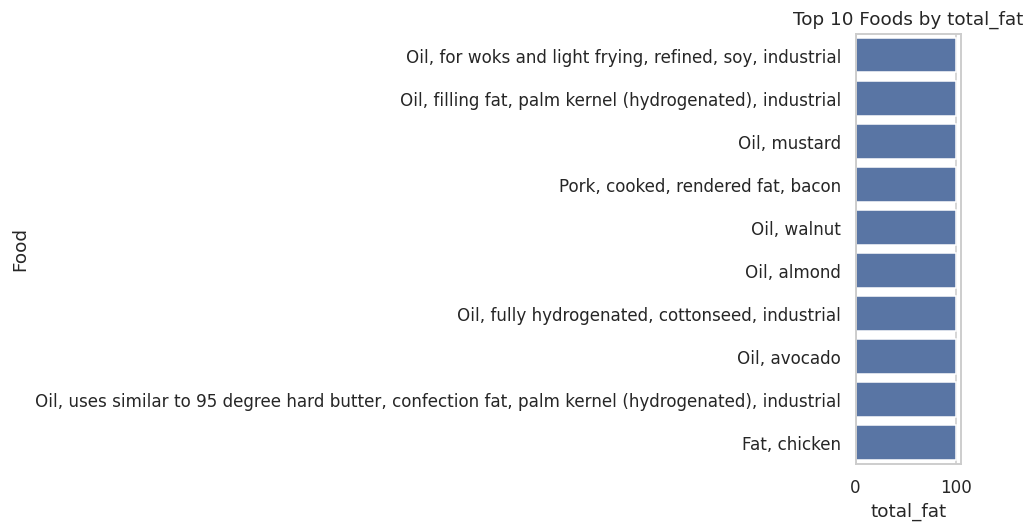

,Food Name,total_fat
5011,"Oil, for woks and light frying, refined, soy, ...",100.0
5085,"Oil, filling fat, palm kernel (hydrogenated), ...",100.0
606,"Oil, mustard",100.0
1530,"Pork, cooked, rendered fat, bacon",100.0
635,"Oil, walnut",100.0
634,"Oil, almond",100.0
3727,"Oil, fully hydrogenated, cottonseed, industrial",100.0
607,"Oil, avocado",100.0
8782,"Oil, uses similar to 95 degree hard butter, co...",100.0
610,"Fat, chicken",100.0


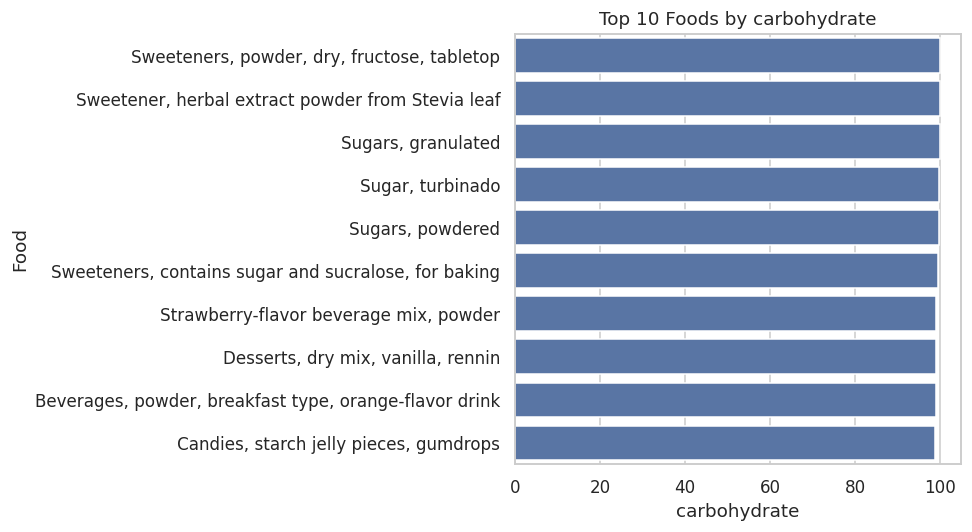

,Food Name,carbohydrate
2976,"Sweeteners, powder, dry, fructose, tabletop",100.00
4744,"Sweetener, herbal extract powder from Stevia leaf",100.00
328,"Sugars, granulated",99.98
435,"Sugar, turbinado",99.80
407,"Sugars, powdered",99.77
4293,"Sweeteners, contains sugar and sucralose, for ...",99.53
2326,"Strawberry-flavor beverage mix, powder",99.10
1494,"Desserts, dry mix, vanilla, rennin",99.00
5376,"Beverages, powder, breakfast type, orange-flav...",98.94
2228,"Candies, starch jelly pieces, gumdrops",98.90


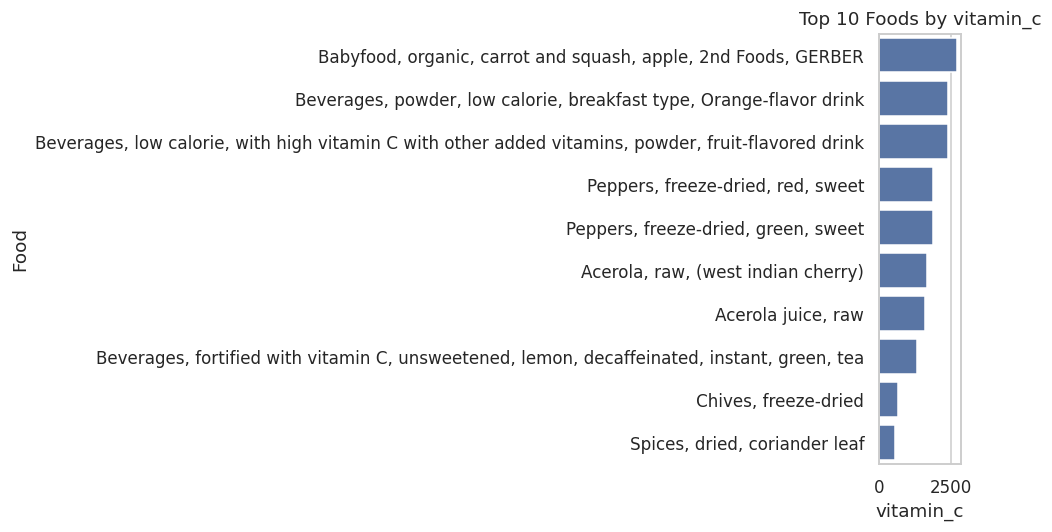

,Food Name,vitamin_c
5617,"Babyfood, organic, carrot and squash, apple, 2...",2732.0
6463,"Beverages, powder, low calorie, breakfast type...",2400.0
8161,"Beverages, low calorie, with high vitamin C wi...",2400.0
1607,"Peppers, freeze-dried, red, sweet",1900.0
2624,"Peppers, freeze-dried, green, sweet",1900.0
1436,"Acerola, raw, (west indian cherry)",1677.6
285,"Acerola juice, raw",1600.0
7839,"Beverages, fortified with vitamin C, unsweeten...",1342.3
153,"Chives, freeze-dried",660.0
745,"Spices, dried, coriander leaf",566.7


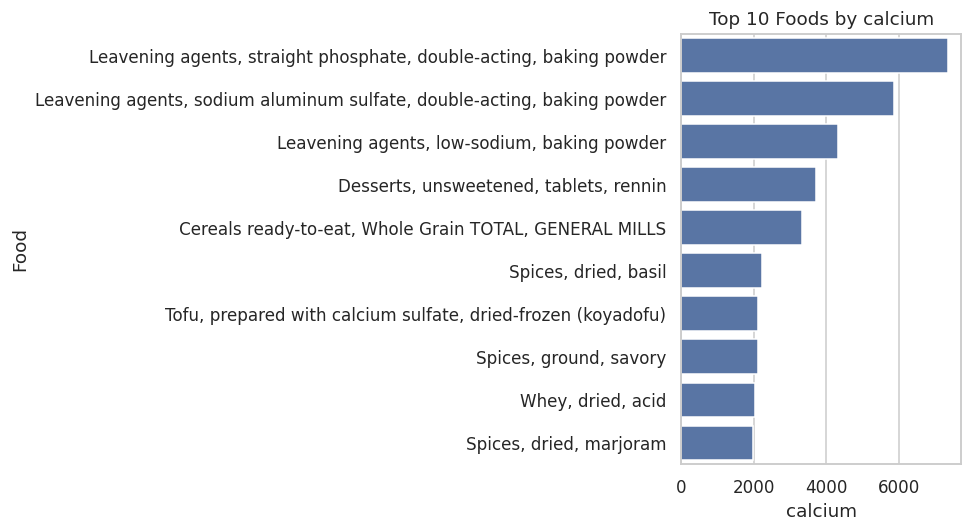

,Food Name,calcium
6553,"Leavening agents, straight phosphate, double-a...",7364.0
6151,"Leavening agents, sodium aluminum sulfate, dou...",5876.0
2938,"Leavening agents, low-sodium, baking powder",4332.0
2261,"Desserts, unsweetened, tablets, rennin",3733.0
5383,"Cereals ready-to-eat, Whole Grain TOTAL, GENER...",3333.0
151,"Spices, dried, basil",2240.0
5929,"Tofu, prepared with calcium sulfate, dried-fro...",2134.0
22,"Spices, ground, savory",2132.0
380,"Whey, dried, acid",2054.0
1250,"Spices, dried, marjoram",1990.0


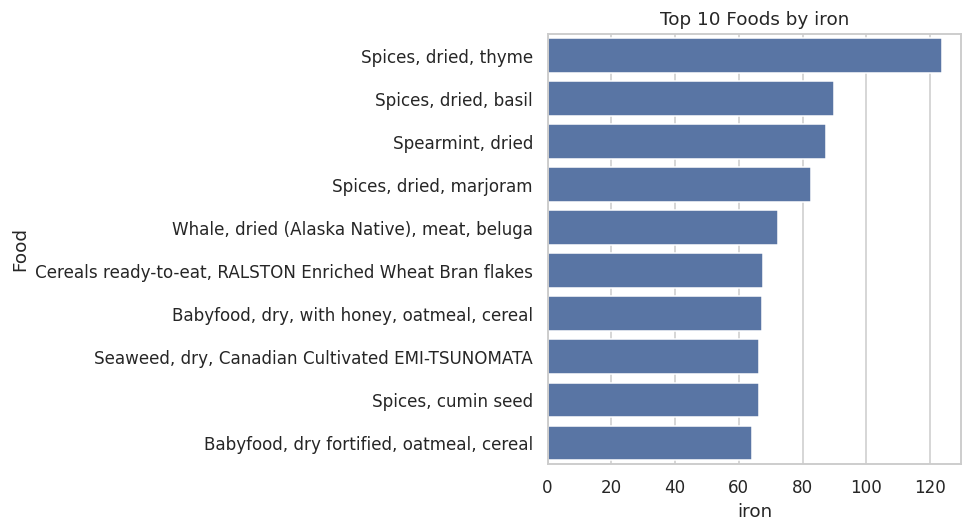

,Food Name,iron
142,"Spices, dried, thyme",123.60
151,"Spices, dried, basil",89.80
413,"Spearmint, dried",87.47
1250,"Spices, dried, marjoram",82.71
3089,"Whale, dried (Alaska Native), meat, beluga",72.35
5120,"Cereals ready-to-eat, RALSTON Enriched Wheat B...",67.67
3173,"Babyfood, dry, with honey, oatmeal, cereal",67.23
3660,"Seaweed, dry, Canadian Cultivated EMI-TSUNOMATA",66.38
311,"Spices, cumin seed",66.36
3369,"Babyfood, dry fortified, oatmeal, cereal",64.07


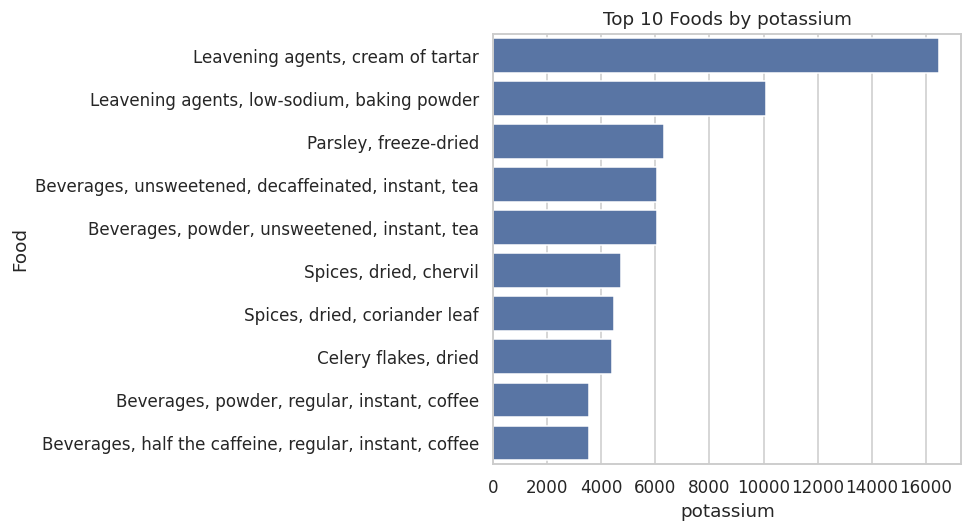

,Food Name,potassium
1643,"Leavening agents, cream of tartar",16500.0
2938,"Leavening agents, low-sodium, baking powder",10100.0
109,"Parsley, freeze-dried",6300.0
4433,"Beverages, unsweetened, decaffeinated, instant...",6040.0
2852,"Beverages, powder, unsweetened, instant, tea",6040.0
1316,"Spices, dried, chervil",4740.0
745,"Spices, dried, coriander leaf",4466.0
194,"Celery flakes, dried",4388.0
2896,"Beverages, powder, regular, instant, coffee",3535.0
5340,"Beverages, half the caffeine, regular, instant...",3535.0


In [15]:
# Top foods for selected nutrients. This is descriptive and should be interpreted
# with serving size and units in mind.
nutrients_to_rank = ["calories", "protein", "fiber", "total_fat", "carbohydrate", "vitamin_c", "calcium", "iron", "potassium"]

for nutrient in nutrients_to_rank:
    if nutrient not in df_eda.columns:
        continue
    plot_data = df_eda[["Food Name", nutrient]].dropna().sort_values(nutrient, ascending=False).head(10)
    if plot_data.empty:
        continue
    plt.figure(figsize=(9, 5))
    sns.barplot(data=plot_data, x=nutrient, y="Food Name")
    plt.title(f"Top 10 Foods by {nutrient}")
    plt.xlabel(nutrient)
    plt.ylabel("Food")
    plt.tight_layout()
    plt.show()
    display(plot_data)

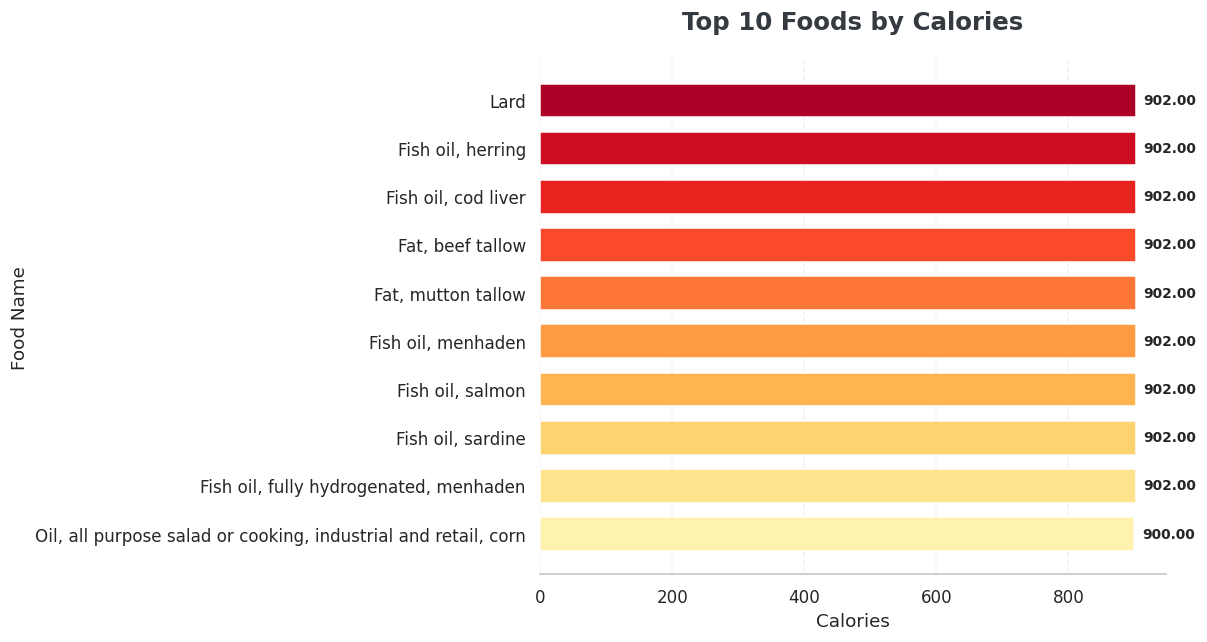

,Food Name,calories
0,"Oil, all purpose salad or cooking, industrial ...",900
1,"Fish oil, fully hydrogenated, menhaden",902
2,"Fish oil, sardine",902
3,"Fish oil, salmon",902
4,"Fish oil, menhaden",902
5,"Fat, mutton tallow",902
6,"Fat, beef tallow",902
7,"Fish oil, cod liver",902
8,"Fish oil, herring",902
9,Lard,902


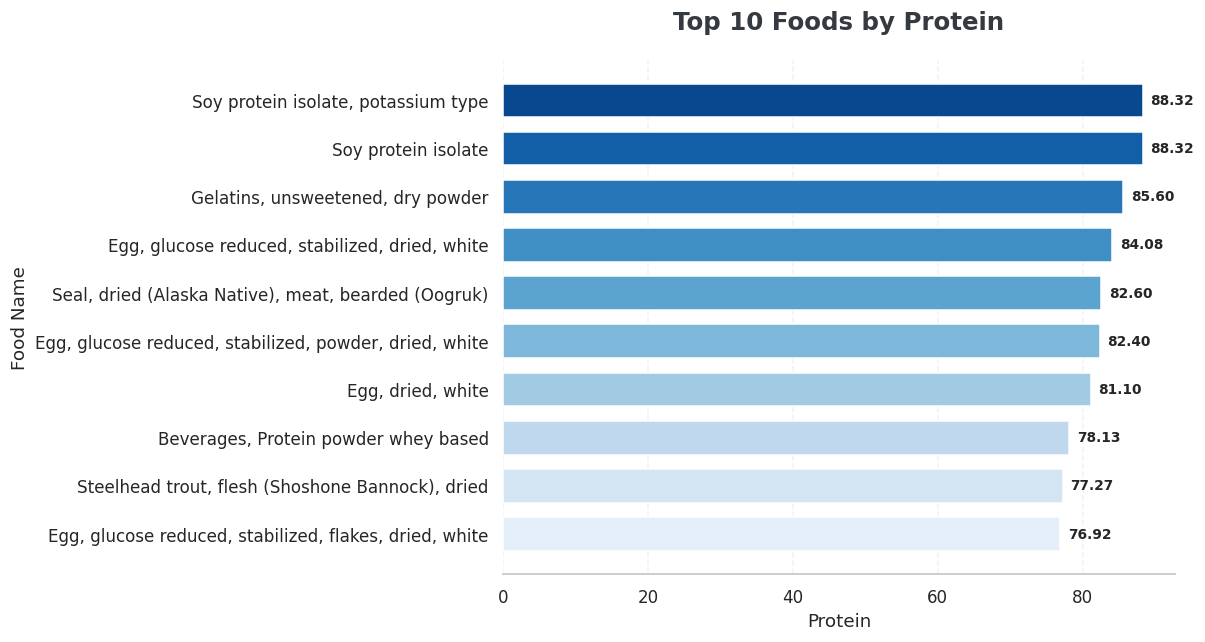

,Food Name,protein
0,"Egg, glucose reduced, stabilized, flakes, drie...",76.92
1,"Steelhead trout, flesh (Shoshone Bannock), dried",77.27
2,"Beverages, Protein powder whey based",78.13
3,"Egg, dried, white",81.10
4,"Egg, glucose reduced, stabilized, powder, drie...",82.40
5,"Seal, dried (Alaska Native), meat, bearded (Oo...",82.60
6,"Egg, glucose reduced, stabilized, dried, white",84.08
7,"Gelatins, unsweetened, dry powder",85.60
8,Soy protein isolate,88.32
9,"Soy protein isolate, potassium type",88.32


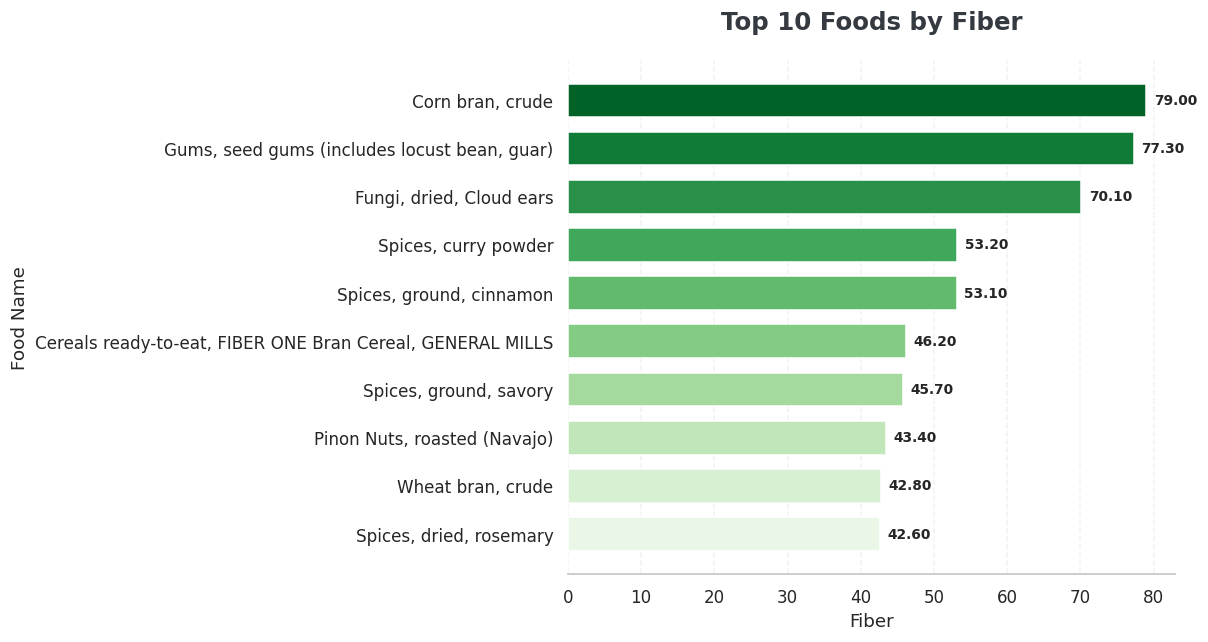

,Food Name,fiber
0,"Spices, dried, rosemary",42.6
1,"Wheat bran, crude",42.8
2,"Pinon Nuts, roasted (Navajo)",43.4
3,"Spices, ground, savory",45.7
4,"Cereals ready-to-eat, FIBER ONE Bran Cereal, G...",46.2
5,"Spices, ground, cinnamon",53.1
6,"Spices, curry powder",53.2
7,"Fungi, dried, Cloud ears",70.1
8,"Gums, seed gums (includes locust bean, guar)",77.3
9,"Corn bran, crude",79.0


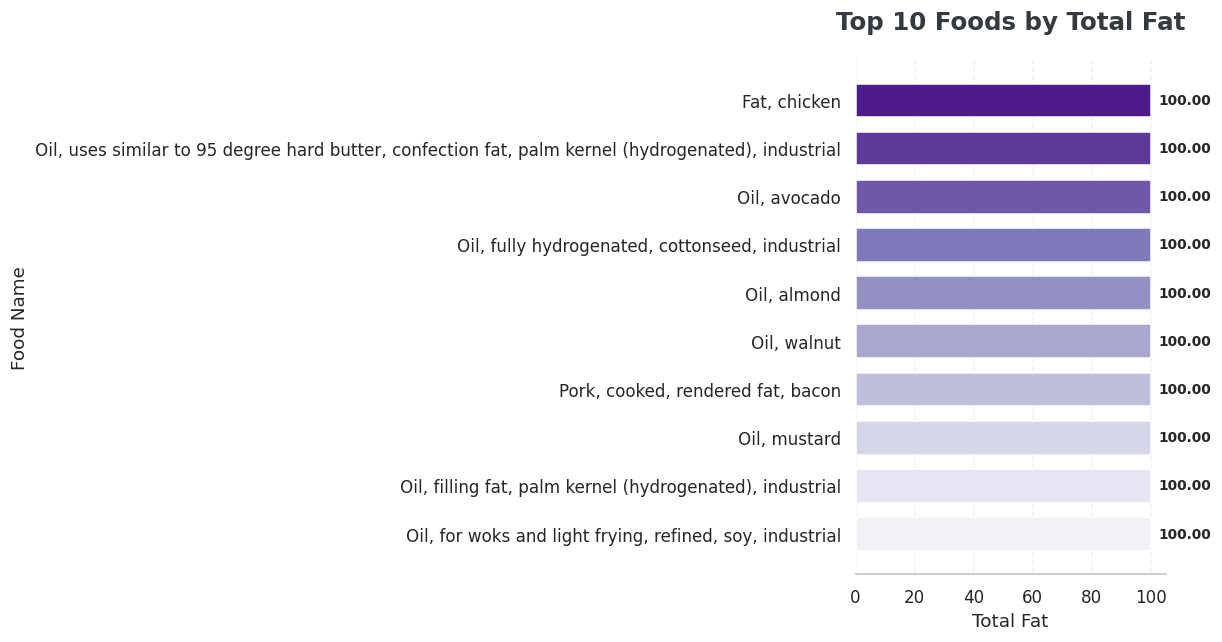

,Food Name,total_fat
0,"Oil, for woks and light frying, refined, soy, ...",100.0
1,"Oil, filling fat, palm kernel (hydrogenated), ...",100.0
2,"Oil, mustard",100.0
3,"Pork, cooked, rendered fat, bacon",100.0
4,"Oil, walnut",100.0
5,"Oil, almond",100.0
6,"Oil, fully hydrogenated, cottonseed, industrial",100.0
7,"Oil, avocado",100.0
8,"Oil, uses similar to 95 degree hard butter, co...",100.0
9,"Fat, chicken",100.0


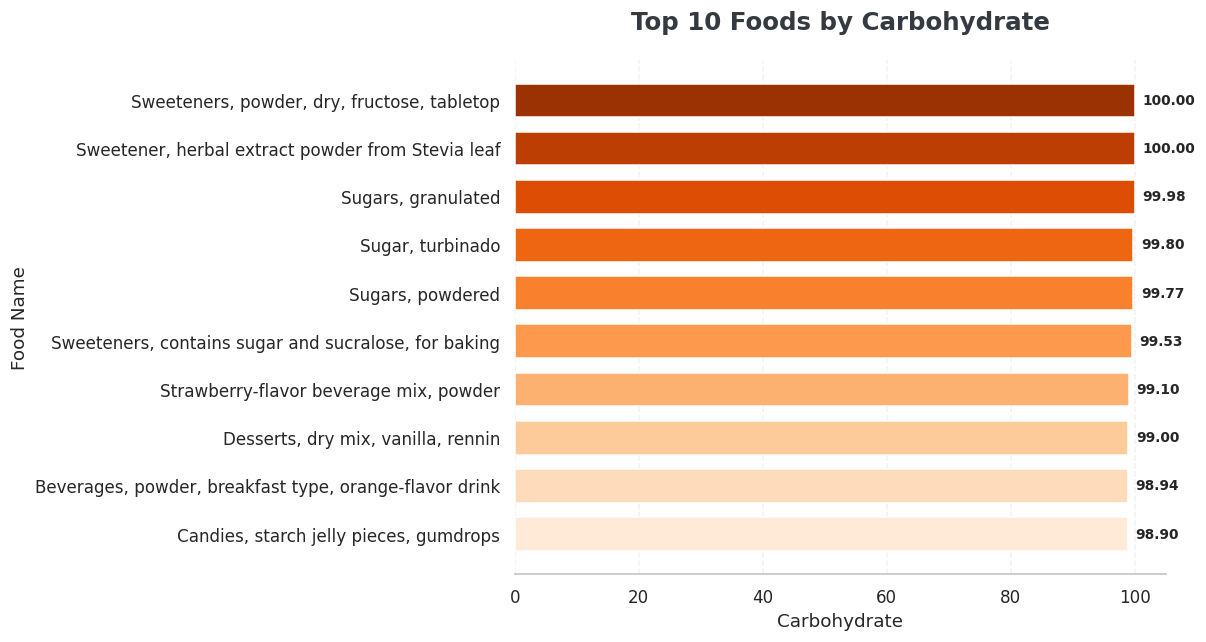

,Food Name,carbohydrate
0,"Candies, starch jelly pieces, gumdrops",98.90
1,"Beverages, powder, breakfast type, orange-flav...",98.94
2,"Desserts, dry mix, vanilla, rennin",99.00
3,"Strawberry-flavor beverage mix, powder",99.10
4,"Sweeteners, contains sugar and sucralose, for ...",99.53
5,"Sugars, powdered",99.77
6,"Sugar, turbinado",99.80
7,"Sugars, granulated",99.98
8,"Sweetener, herbal extract powder from Stevia leaf",100.00
9,"Sweeteners, powder, dry, fructose, tabletop",100.00


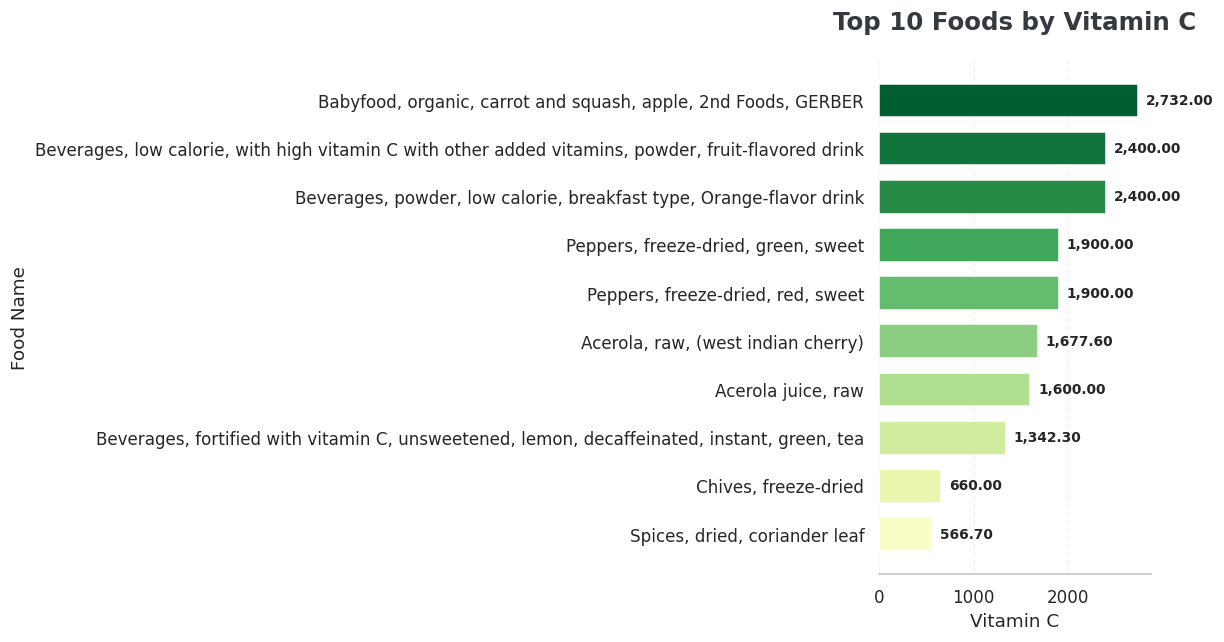

,Food Name,vitamin_c
0,"Spices, dried, coriander leaf",566.7
1,"Chives, freeze-dried",660.0
2,"Beverages, fortified with vitamin C, unsweeten...",1342.3
3,"Acerola juice, raw",1600.0
4,"Acerola, raw, (west indian cherry)",1677.6
5,"Peppers, freeze-dried, red, sweet",1900.0
6,"Peppers, freeze-dried, green, sweet",1900.0
7,"Beverages, powder, low calorie, breakfast type...",2400.0
8,"Beverages, low calorie, with high vitamin C wi...",2400.0
9,"Babyfood, organic, carrot and squash, apple, 2...",2732.0


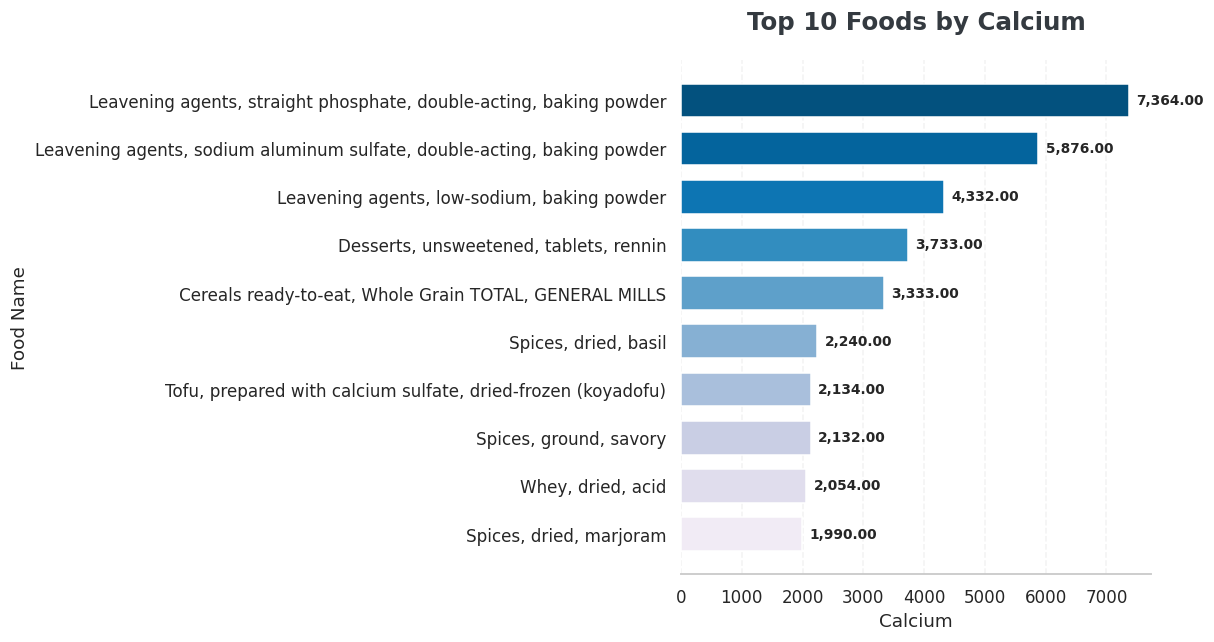

,Food Name,calcium
0,"Spices, dried, marjoram",1990.0
1,"Whey, dried, acid",2054.0
2,"Spices, ground, savory",2132.0
3,"Tofu, prepared with calcium sulfate, dried-fro...",2134.0
4,"Spices, dried, basil",2240.0
5,"Cereals ready-to-eat, Whole Grain TOTAL, GENER...",3333.0
6,"Desserts, unsweetened, tablets, rennin",3733.0
7,"Leavening agents, low-sodium, baking powder",4332.0
8,"Leavening agents, sodium aluminum sulfate, dou...",5876.0
9,"Leavening agents, straight phosphate, double-a...",7364.0


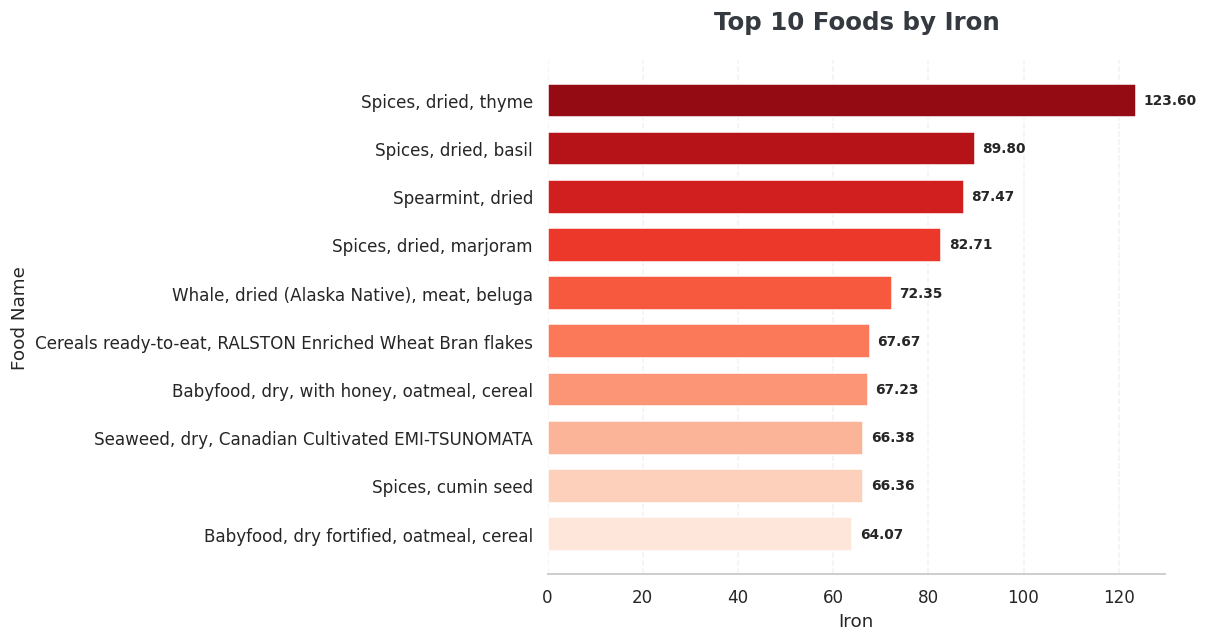

,Food Name,iron
0,"Babyfood, dry fortified, oatmeal, cereal",64.07
1,"Spices, cumin seed",66.36
2,"Seaweed, dry, Canadian Cultivated EMI-TSUNOMATA",66.38
3,"Babyfood, dry, with honey, oatmeal, cereal",67.23
4,"Cereals ready-to-eat, RALSTON Enriched Wheat B...",67.67
5,"Whale, dried (Alaska Native), meat, beluga",72.35
6,"Spices, dried, marjoram",82.71
7,"Spearmint, dried",87.47
8,"Spices, dried, basil",89.80
9,"Spices, dried, thyme",123.60


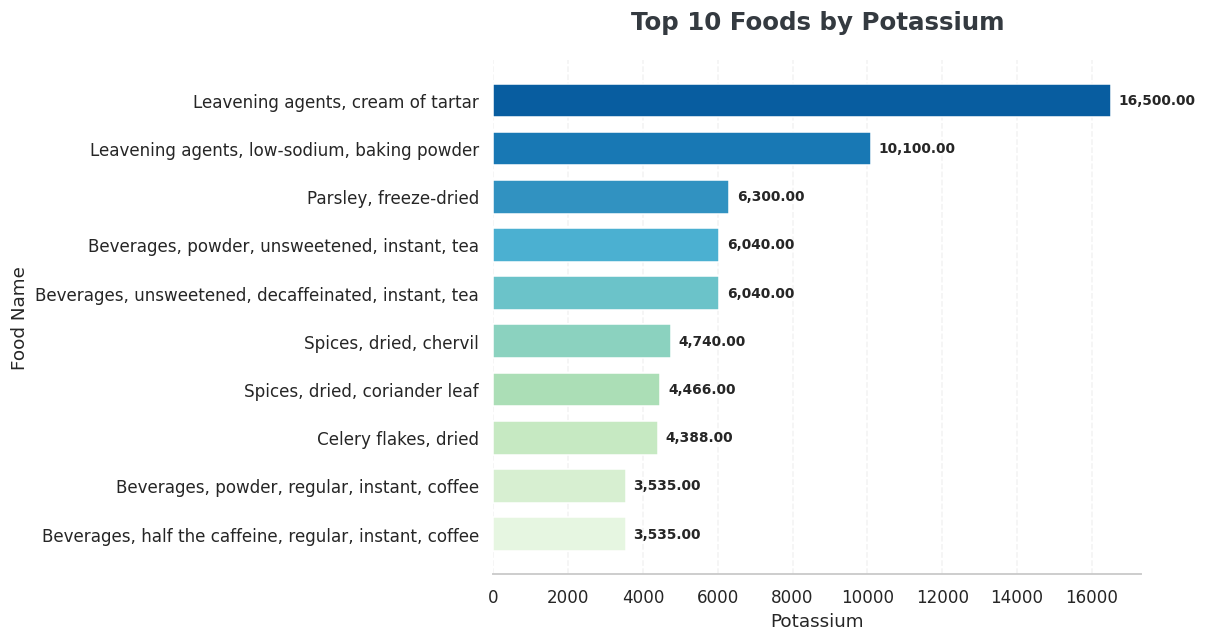

,Food Name,potassium
0,"Beverages, half the caffeine, regular, instant...",3535.0
1,"Beverages, powder, regular, instant, coffee",3535.0
2,"Celery flakes, dried",4388.0
3,"Spices, dried, coriander leaf",4466.0
4,"Spices, dried, chervil",4740.0
5,"Beverages, unsweetened, decaffeinated, instant...",6040.0
6,"Beverages, powder, unsweetened, instant, tea",6040.0
7,"Parsley, freeze-dried",6300.0
8,"Leavening agents, low-sodium, baking powder",10100.0
9,"Leavening agents, cream of tartar",16500.0


In [20]:
# ==========================================
# TOP 10 FOODS BY NUTRIENT
# ==========================================

nutrients_to_rank = [
    "calories",
    "protein",
    "fiber",
    "total_fat",
    "carbohydrate",
    "vitamin_c",
    "calcium",
    "iron",
    "potassium"
]

# Colour palettes for different nutrients
nutrient_colors = {
    "calories": "YlOrRd",
    "protein": "Blues",
    "fiber": "Greens",
    "total_fat": "Purples",
    "carbohydrate": "Oranges",
    "vitamin_c": "YlGn",
    "calcium": "PuBu",
    "iron": "Reds",
    "potassium": "GnBu"
}

for nutrient in nutrients_to_rank:

    if nutrient not in df_eda.columns:
        continue

    plot_data = (
        df_eda[["Food Name", nutrient]]
        .dropna()
        .sort_values(nutrient, ascending=False)
        .head(10)
        .sort_values(nutrient, ascending=True)
    )

    if plot_data.empty:
        continue

    # Select gradient palette
    cmap = sns.color_palette(
        nutrient_colors.get(nutrient, "viridis"),
        n_colors=len(plot_data)
    )

    fig, ax = plt.subplots(figsize=(11, 6))

    bars = ax.barh(
        plot_data["Food Name"],
        plot_data[nutrient],
        color=cmap,
        edgecolor="white",
        linewidth=1,
        height=0.7
    )

    # Add value labels
    ax.bar_label(
        bars,
        labels=[f"{v:,.2f}" for v in plot_data[nutrient]],
        padding=5,
        fontsize=9,
        fontweight="bold"
    )

    # Titles and labels
    ax.set_title(
        f"Top 10 Foods by {nutrient.replace('_', ' ').title()}",
        fontsize=16,
        fontweight="bold",
        color="#343A40",
        pad=20
    )

    ax.set_xlabel(
        nutrient.replace("_", " ").title(),
        fontsize=12,
        fontweight="medium"
    )

    ax.set_ylabel("Food Name", fontsize=12)

    # Clean visual style
    ax.grid(axis="x", linestyle="--", alpha=0.25)
    ax.grid(axis="y", visible=False)

    sns.despine(left=True, top=True, right=True)

    plt.tight_layout()
    plt.show()

    # Display the ranked data
    display(
        plot_data.reset_index(drop=True)
    )

## 16. Pairwise relationships among major macronutrients

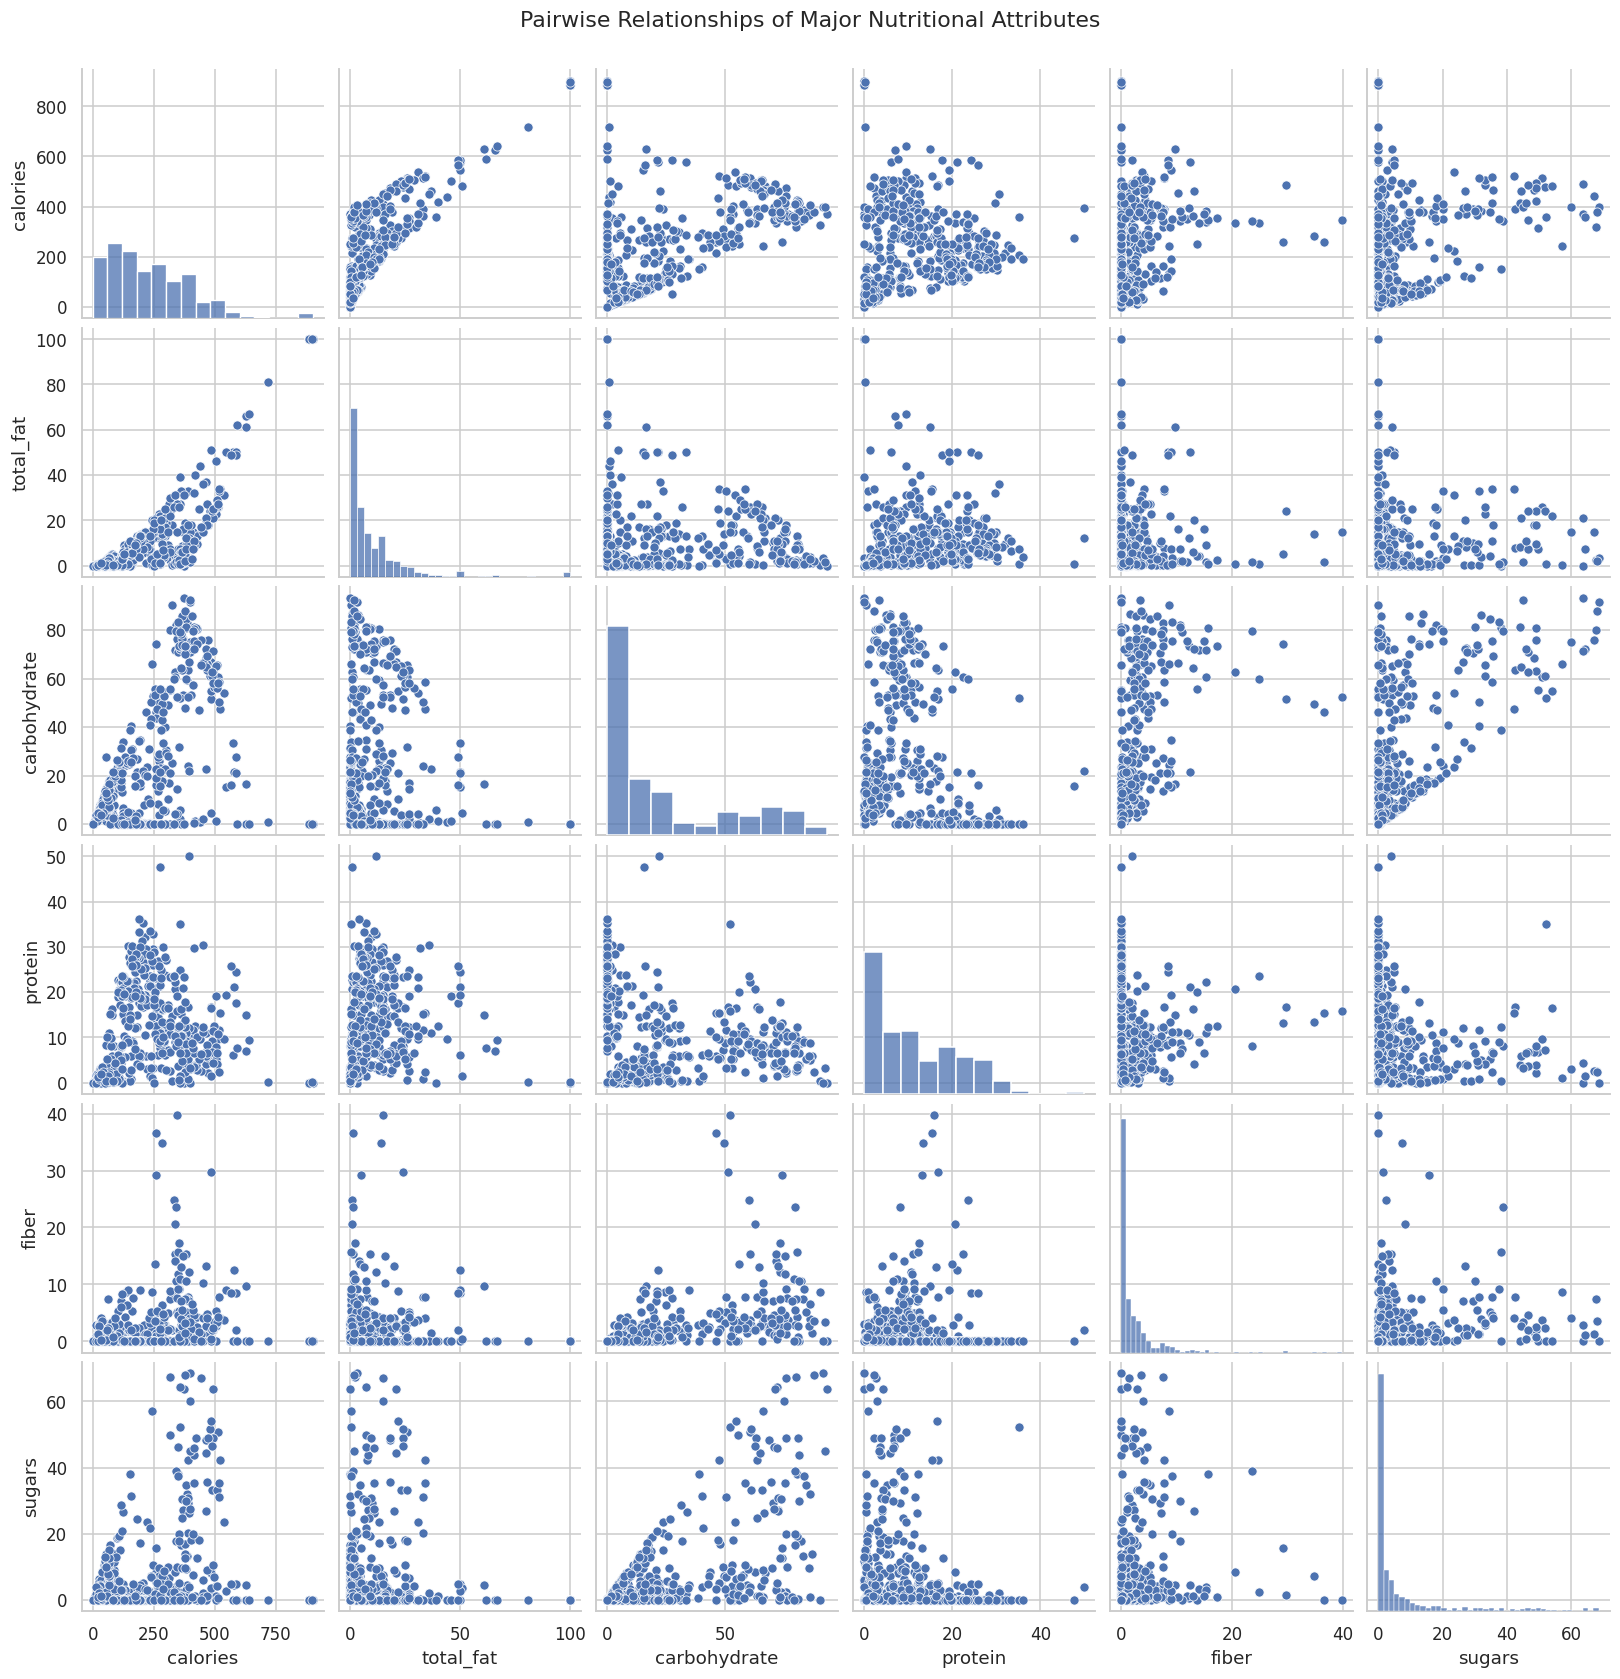

In [16]:
major_nutrients = [col for col in ["calories", "total_fat", "carbohydrate", "protein", "fiber", "sugars"] if col in numeric_df.columns]

if len(major_nutrients) >= 2:
    pair_data = df_eda[major_nutrients].dropna()
    if len(pair_data) > 500:
        pair_data = pair_data.sample(500, random_state=42)
    sns.pairplot(pair_data, diag_kind="hist")
    plt.suptitle("Pairwise Relationships of Major Nutritional Attributes", y=1.02)
    plt.show()

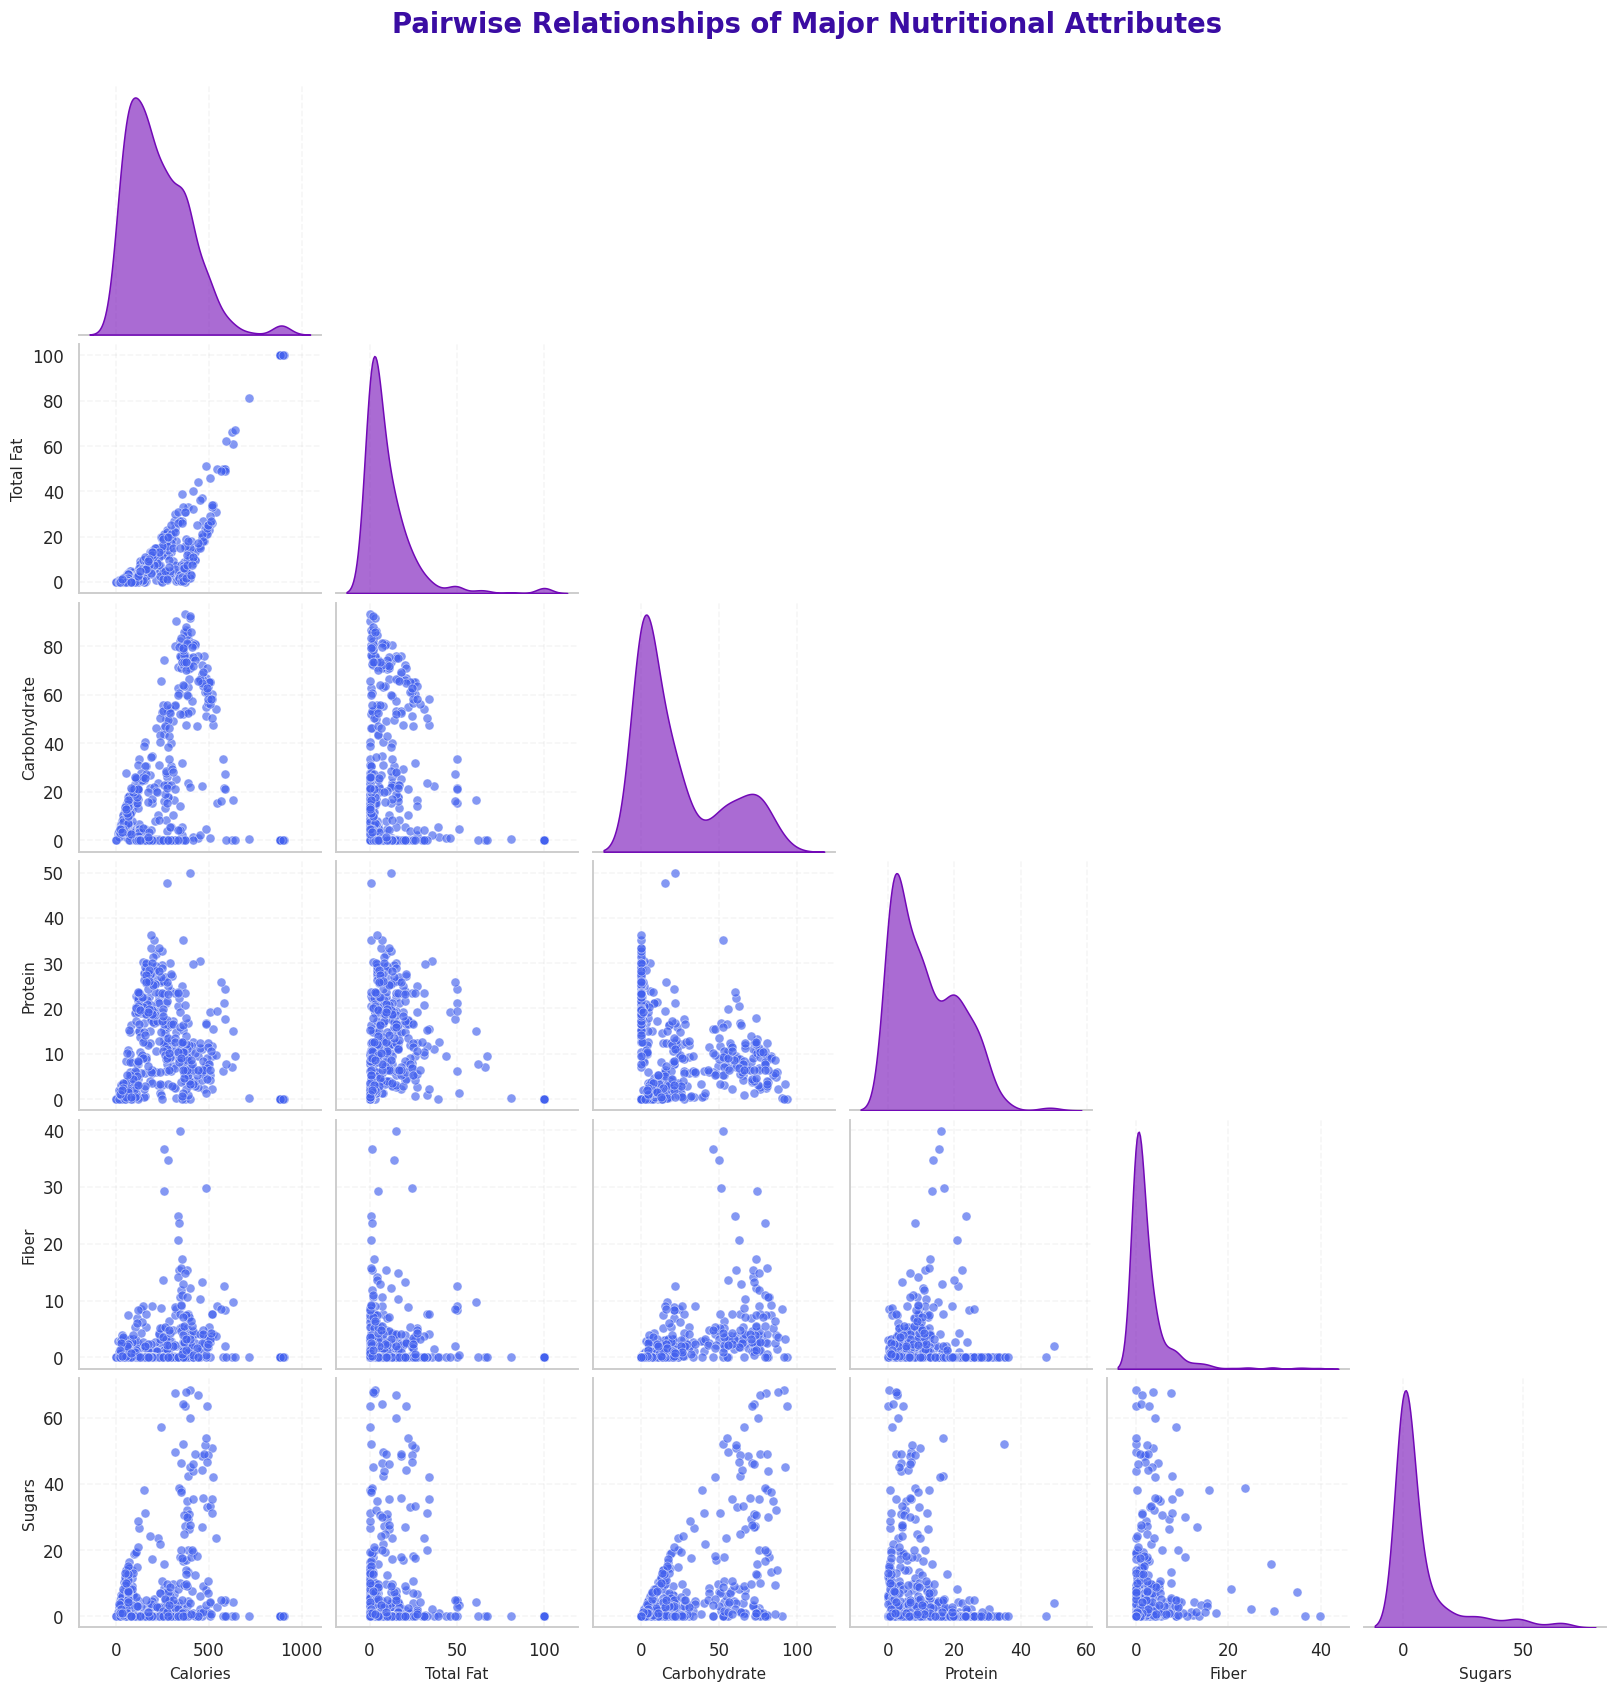

In [21]:
# ==========================================
# PAIRWISE RELATIONSHIPS OF MAJOR NUTRIENTS
# ==========================================

major_nutrients = [
    col for col in [
        "calories",
        "total_fat",
        "carbohydrate",
        "protein",
        "fiber",
        "sugars"
    ]
    if col in numeric_df.columns
]

if len(major_nutrients) >= 2:

    pair_data = df_eda[major_nutrients].dropna()

    # Sample data if dataset is large
    if len(pair_data) > 500:
        pair_data = pair_data.sample(
            500,
            random_state=42
        )

    # Create pairplot
    pair_plot = sns.pairplot(
        pair_data,
        diag_kind="kde",
        corner=True,
        plot_kws={
            "alpha": 0.65,
            "s": 35,
            "color": "#4361EE",
            "edgecolor": "white",
            "linewidth": 0.4
        },
        diag_kws={
            "fill": True,
            "color": "#7209B7",
            "alpha": 0.6
        }
    )

    # Improve titles and overall appearance
    pair_plot.fig.suptitle(
        "Pairwise Relationships of Major Nutritional Attributes",
        fontsize=18,
        fontweight="bold",
        color="#3A0CA3",
        y=1.03
    )

    # Improve axis labels
    for ax in pair_plot.axes.flatten():

        if ax is not None:

            ax.set_xlabel(
                ax.get_xlabel().replace("_", " ").title(),
                fontsize=10
            )

            ax.set_ylabel(
                ax.get_ylabel().replace("_", " ").title(),
                fontsize=10
            )

            ax.grid(
                True,
                linestyle="--",
                alpha=0.2
            )

    plt.show()

## 17. Summary of the original dataset

In [17]:
print("EDA SUMMARY")
print("=" * 50)
print(f"Records: {df.shape[0]}")
print(f"Attributes: {df.shape[1]}")
print(f"Exact duplicate rows: {df.duplicated().sum()}")
print(f"Total missing cells: {df.isna().sum().sum()}")
print(f"Numeric attributes analysed: {numeric_df.shape[1]}")

if "Food Name" in df.columns:
    print(f"Unique food names: {df['Food Name'].nunique()}")

print("\\nAttributes with missing data:")
display(missing_summary[missing_summary["Missing Values"] > 0])

print("\\nHighest average numerical attributes (units differ, so do not compare directly):")
display(numeric_df.mean().sort_values(ascending=False).to_frame("Mean").head(10))

EDA SUMMARY
Records: 8789
Attributes: 15
Exact duplicate rows: 0
Total missing cells: 1590
Numeric attributes analysed: 13
Unique food names: 8789
\nAttributes with missing data:


,Missing Values,Missing Percentage (%)
saturated_fat,1590,18.09


\nHighest average numerical attributes (units differ, so do not compare directly):


,Mean
sodium,306.353851
potassium,265.251223
calories,226.283878
calcium,73.317328
folate,44.085561
carbohydrate,22.121915
protein,11.345616
total_fat,10.556855
vitamin_c,8.356548
sugars,6.756293


## 18. Findings and interpretation (complete after running)

Use the actual output of this notebook to write your findings. Avoid claiming that a correlation proves causation.

Suggested structure:

1. **Dataset size:** The original dataset contains ___ records and ___ attributes.
2. **Data quality:** ___ missing values and ___ duplicate records were identified.
3. **Distribution:** The attribute ___ showed a ___ distribution, while ___ had notable extreme values.
4. **Relationship:** ___ and ___ had a correlation of ___, suggesting ___.
5. **Outliers:** IQR analysis identified potential outliers in ___; these may represent valid nutrient-rich foods and require source verification.
6. **Limitations:** Serving sizes and nutrient units must be checked before direct comparisons. The original dataset does not contain API-derived information.

## 19. Save EDA outputs

The following cell saves the cleaned analysis copy and summary tables to a folder in Google Drive. The original CSV remains unchanged.


In [18]:
output_dir = Path("/content/drive/MyDrive/phase1/eda_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

df_eda.to_csv(output_dir / "original_dataset_eda_cleaned.csv", index=False)
descriptive_stats.to_csv(output_dir / "descriptive_statistics.csv")
missing_summary.to_csv(output_dir / "missing_values_summary.csv")
outlier_summary.to_csv(output_dir / "outlier_summary_iqr.csv")
corr.to_csv(output_dir / "correlation_matrix.csv")

print("EDA output files saved to:", output_dir)

EDA output files saved to: /content/drive/MyDrive/phase1/eda_outputs


## Conclusion

This notebook provides the baseline EDA for the original nutrition dataset. The results establish the dataset's structure, data quality, nutritional distributions, outliers, and relationships among variables. These findings can be used in Part A of the report and later compared with the API-enriched fused dataset in Parts D–F.

**Important:** This notebook analyses the original dataset only. API collection, data fusion, and fused-dataset EDA should be documented in separate notebooks or later sections.
